# Lab 4: Non-negative Matrix Factorization

Welcome to the advanced Machine Learning Course.

The objective of this lab session is to code a few regression algorithms and to apply them to synthetic and real datasets.

Please put **"ML - MDS - TD4"** in the mail subject or I might lose your work (which means 0) and send it to ludovic.trautmann@inria.fr

Please label your notebook **"L4_familyname1_familyname2.ipynb"**.

Make sure to put comments in your code. **Raw numerical results or plots without comments will have almost no value in the grading. Please make sure to comment yout results.**

In [2]:
import numpy             as np
import matplotlib.pyplot as plt
import seaborn           as sns
from sklearn.utils       import check_random_state
from sklearn.datasets    import fetch_olivetti_faces

%matplotlib inline
sns.set_context('poster')
sns.set_color_codes()
plot_kwds        = {'alpha' : 0.25, 's' : 80, 'linewidths':0}

dataset          = fetch_olivetti_faces(shuffle=True)
faces            = dataset.data.T #on représente chaque image par une colonne, en accord avec le cours
faces[3523][338] = 1e-2 #l'un des éléments de faces est nul, ce qui bloque la divergence de KL

## NMF

Regularized Froebnius Loss: $\mathcal{L}(W, H) = \frac{1}{2}\|X-W H\|_{F}^{2}+ \frac{\mu}{2}\|H\|_{F}^{2}+\lambda\|H\|_{1}+\frac{\nu}{2}\|W\|_{F}^{2}$

KL Loss : $\mathcal{L}(W,H) = \mathcal{KL}(X, W H)$



Fill in the following NMF class:

In [ ]:
from scipy.optimize import nnls
from scipy.special  import xlogy
class MYNMF():
    
    """
    
    Attributes:                                                                                 
    -----------                                                Default value
    n_components_ : integer,  unknown dimension of W and H   | 20                
    max_iter_     : integer,  maximum number of iterations   | 60
    epsilon_      : float,    epsilon coefficient            | 1e-4
    loss_         : str,      {"Frobenius", "KL"}            | Frobenius
    D_            : np.array, W Matrix factor                | None
    S_            : np.array, H Matrix factor                | None
    D_history     : list,     W Matrix history               | []
    S_history     : list,     H Matrix history               | []
    loss_history  : list,     history of loss                | []
    random_state  : int,      for the random initialization  | 42
    """
    
    def __init__(self, n_components=20, max_iter=200, epsilon = 1e-5, loss = "Frobenius", random_state=42):
        
        self.n_components_ = n_components
        self.max_iter_     = max_iter
        self.epsilon_      = epsilon
        self.loss_         = loss
        self.D_            = None
        self.S_            = None
        self.D_history     = []
        self.S_history     = []
        self.loss_history  = []
        self.random_state  = random_state
        self.components_   = None    # shape (r, p)
        
    def fit_transform(self, data, mu=5e-3,  nu=5e-3, lambd=1e-3):
        
        """ Find the factor matrices D and S for matrix factorization of data
        
        Parameters:
        -----------                                 Default value       
        data  : (p, n) np.arrayData, matrix       | 
        mu    : float, regularization parameter   | 5e-3
        lambd : float, regularization parameter   | 1e-3
        nu    : float, regularization parameter   | 5e-3
        
        Returns:
        -----
        embedding: (p, r) np.array
                    Embedding matrix        
        """        
        eps = 1e-10  # évite les divisions par zéro et log(0) pour la KL
        W = np.random.RandomState(self.random_state).rand(data.shape[0], self.n_components_)
        H = np.random.RandomState(self.random_state).rand(self.n_components_, data.shape[1])

        if self.loss_ == "Frobenius":
            for i in range(self.max_iter_):
                W = W * (data @ H.T) / (W @ H @ H.T + nu * W )
                H = H * (W.T @ data) / (W.T @ W @ H + mu * H + lambd)
                self.D_history.append(W)
                self.S_history.append(H)
                # loss régularisée : nu porte sur W, mu et lambda sur H (cohérent avec les mises à jour)
                loss = 0.5 * np.linalg.norm(data - W @ H, ord='fro')**2 + mu / 2 * np.linalg.norm(H, ord='fro')**2 + lambd * np.sum(H) + nu / 2 * np.linalg.norm(W, ord='fro')**2
                self.loss_history.append(loss)
        elif self.loss_ == "KL":
            for i in range(self.max_iter_):
                W = W * ((data / (W @ H + eps)) @ H.T) / (np.ones(data.shape) @ H.T + nu * W)
                H = H * (W.T @ (data / (W @ H + eps))) / (W.T @ np.ones(data.shape) + mu * H + lambd)
                self.D_history.append(W)
                self.S_history.append(H)
                WH = W @ H + eps
                loss = np.sum(xlogy(data, data / WH) - data + WH) + mu / 2 * np.linalg.norm(H, ord='fro')**2 + lambd * np.sum(H) + nu / 2 * np.linalg.norm(W, ord='fro')**2
                self.loss_history.append(loss)
        self.D_ = W
        self.S_ = H
        self.components_ = W.T   # atomes du dictionnaire, shape (r, p)
        return W
    
    
    def transform(self, data):
        # data: (p,n) , n number of samples, p number of features
        return np.column_stack([nnls(self.D_, data[:, i])[0] for i in range(data.shape[1])])


    def predict_label(self, X):
        """ Predict labels for X : cluster hard-assignment
        
        Parameters:
        -----------
        X: (n, p) np.array, data matrix
        # n number of samples, p number of features
        
        Returns:
        -----
        label assignment : (p, ) np.array, Its elements are the predicted classes, from 0 to r-1
        """
        #TODO
        return np.argmax(self.predict_proba(X), axis=1)
        
    def predict_proba(self, X):
        """ Predict probabilities of different classes for X :  cluster soft-assignment
        
        Parameters:
        -----------
        X: (n, p) np.array
            New data matrix
        # n number of samples, p number of features
        Returns:
        -----
        label_assignment : (n, r) np.array
                          Its elements are the probabilities for different classes
        """
        S = self.transform(X.T)
        sums = np.sum(S, axis=0)
        return (S / sums).T

# Hyperparameter optimization

### Regularization parameter : mu

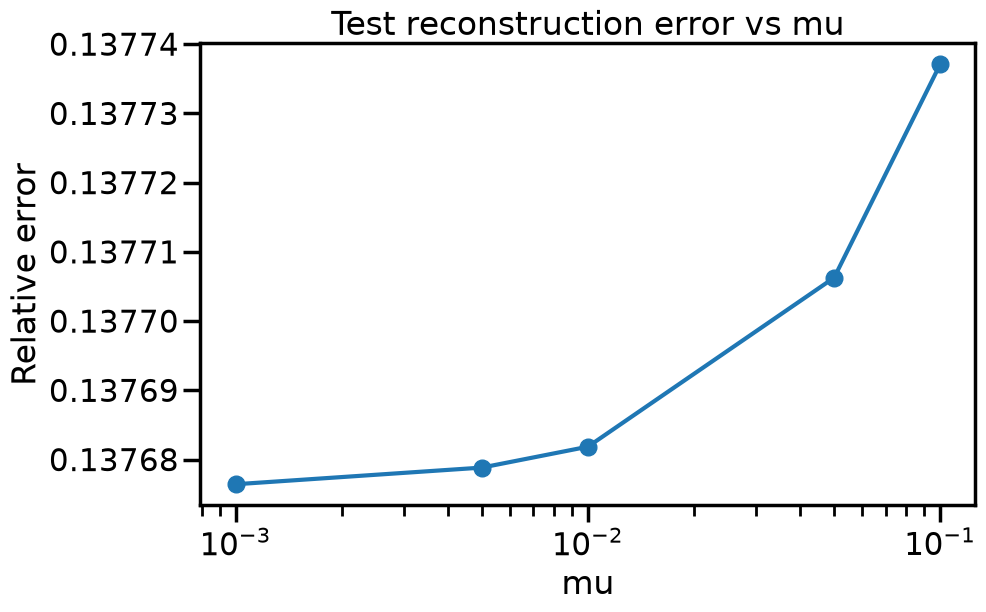

In [4]:
#TODO : find best mu
# split sur les images (colonnes de faces), pas sur les pixels : 320 images en train, 80 en test
train, test = faces[:, :320], faces[:, 320:]

def frob_err(X, Xr):
    """Erreur relative de reconstruction (Frobenius), sans les termes de pénalité"""
    return np.linalg.norm(X - Xr) / np.linalg.norm(X)

def kl_div(X, Xr, eps=1e-10):
    """KL généralisée normalisée par la masse de X"""
    Xr = Xr + eps
    return np.sum(xlogy(X, X / Xr) - X + Xr) / np.sum(X)

mus = [1e-3, 5e-3, 1e-2, 5e-2, 1e-1]
losses = {}
nu = 5e-3
lambd = 1e-3
for mu in mus:
    model = MYNMF(n_components=20, max_iter=200, epsilon = 1e-5, loss = "Frobenius", random_state=42)
    model.fit_transform(train, mu=mu, nu=nu, lambd=lambd)
    reconstructed = model.D_ @ model.transform(test)
    losses[mu] = frob_err(test, reconstructed)

plt.figure(figsize=(10, 6))
plt.plot(list(losses.keys()), list(losses.values()), marker='o')
plt.title('Test reconstruction error vs mu')
plt.xlabel('mu')
plt.ylabel('Relative error')
plt.xscale('log')

In [5]:
model = MYNMF(n_components=20, max_iter=200, epsilon = 1e-5, loss = "Frobenius", random_state=42)
model.fit_transform(train, mu=5e-3, nu=5e-3, lambd=1e-3)
print("D shape:", model.D_.shape)        # (p, r) : dictionnaire
print("S shape:", model.S_.shape)        # (r, n_train)
probs = model.predict_proba(test.T)      # predict_proba attend (n, p)
print("Probs shape:", probs.shape)
preds = model.predict_label(test.T)
print("Preds shape:", preds.shape)
print("Test shape:", test.shape)
print((model.D_ @ model.transform(test)).shape)

D shape: (4096, 20)
S shape: (20, 320)
Probs shape: (80, 20)
Preds shape: (80,)
Test shape: (4096, 80)
(4096, 80)


### Regularization parameter : nu

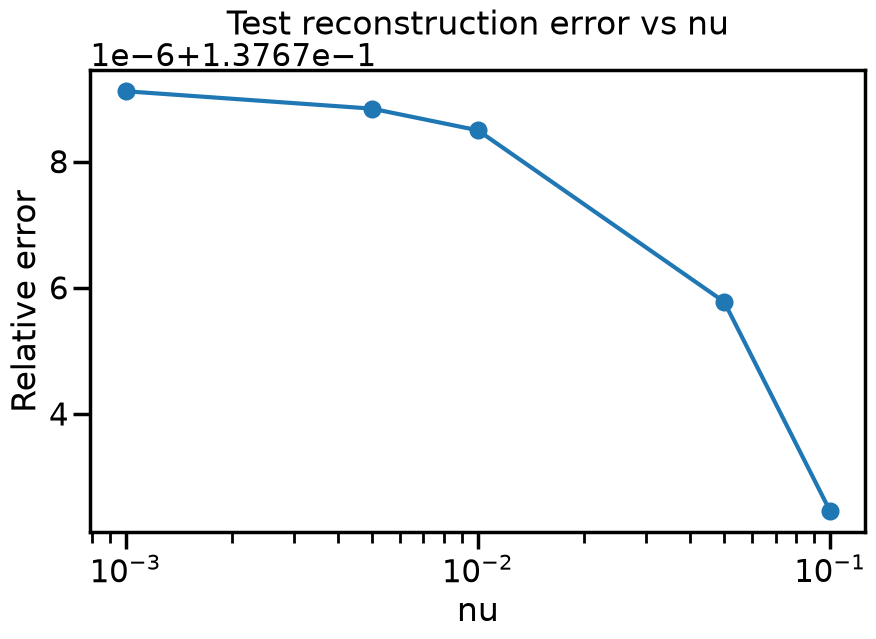

In [6]:
#TODO : find best nu

nus = [1e-3, 5e-3, 1e-2, 5e-2, 1e-1]
losses = {}
mu = 5e-3
lambd = 1e-3
for nu in nus:
    model = MYNMF(n_components=20, max_iter=200, epsilon = 1e-5, loss = "Frobenius", random_state=42)
    model.fit_transform(train, mu=mu, nu=nu, lambd=lambd)
    reconstructed = model.D_ @ model.transform(test)
    # erreur de reconstruction pure : ajouter nu*||W||² pénaliserait artificiellement les grands nu
    losses[nu] = frob_err(test, reconstructed)

plt.figure(figsize=(10, 6))
plt.plot(list(losses.keys()), list(losses.values()), marker='o')
plt.title('Test reconstruction error vs nu')
plt.xlabel('nu')
plt.ylabel('Relative error')
plt.xscale('log')

### Regularization parameter : lambda

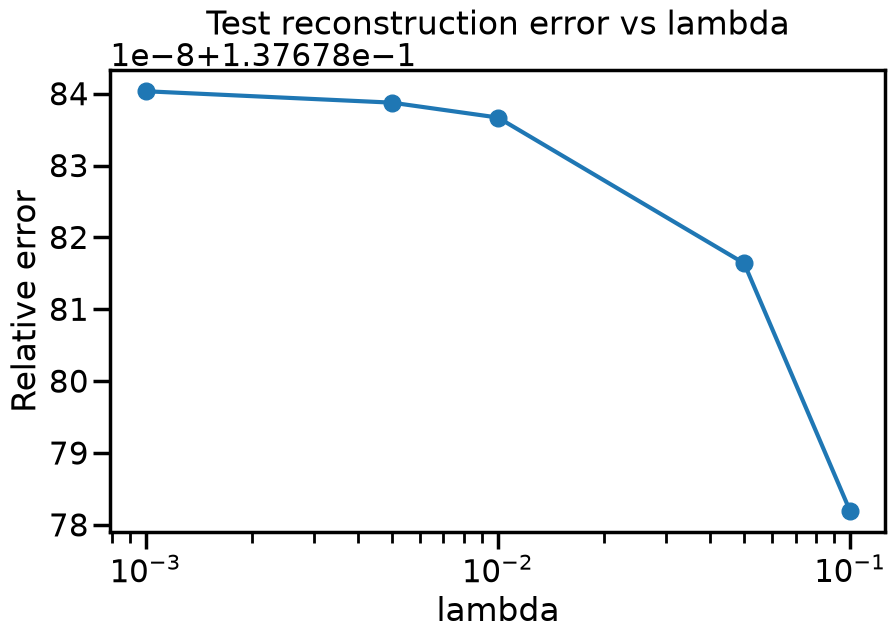

In [7]:
#TODO : find best lambda
lambdas = [1e-3, 5e-3, 1e-2, 5e-2, 1e-1]
losses = {}
mu = 5e-3
nu = 5e-3
for lambd in lambdas:
    model = MYNMF(n_components=20, max_iter=200, epsilon = 1e-5, loss = "Frobenius", random_state=42)
    model.fit_transform(train, mu=mu, nu=nu, lambd=lambd)
    reconstructed = model.D_ @ model.transform(test)
    losses[lambd] = frob_err(test, reconstructed)

plt.figure(figsize=(10, 6))
plt.plot(list(losses.keys()), list(losses.values()), marker='o')
plt.title('Test reconstruction error vs lambda')
plt.xlabel('lambda')
plt.ylabel('Relative error')
plt.xscale('log')

### Number of components

We are going to determine the **optimal number of components** for the factorization by plotting the final loss after 100 epochs for different number of components.
We expect an **elbow curve**, and we will choose the value at the elbow point. Indeed, the higher the number of components is, the more precise the atoms of the dictionary can be, and thus the more precise the reconstructed image will be.
We will find the optimal parameter both for Frobenius and Kullback-Leibler distances.

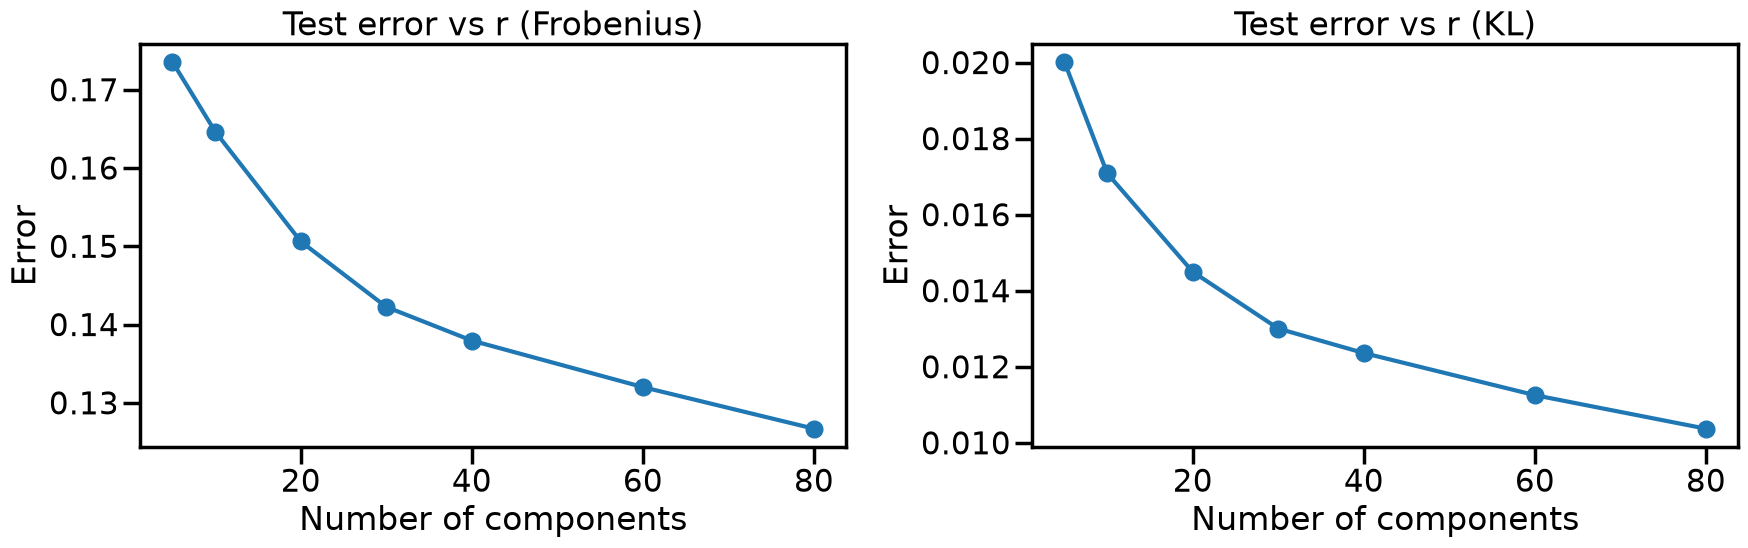

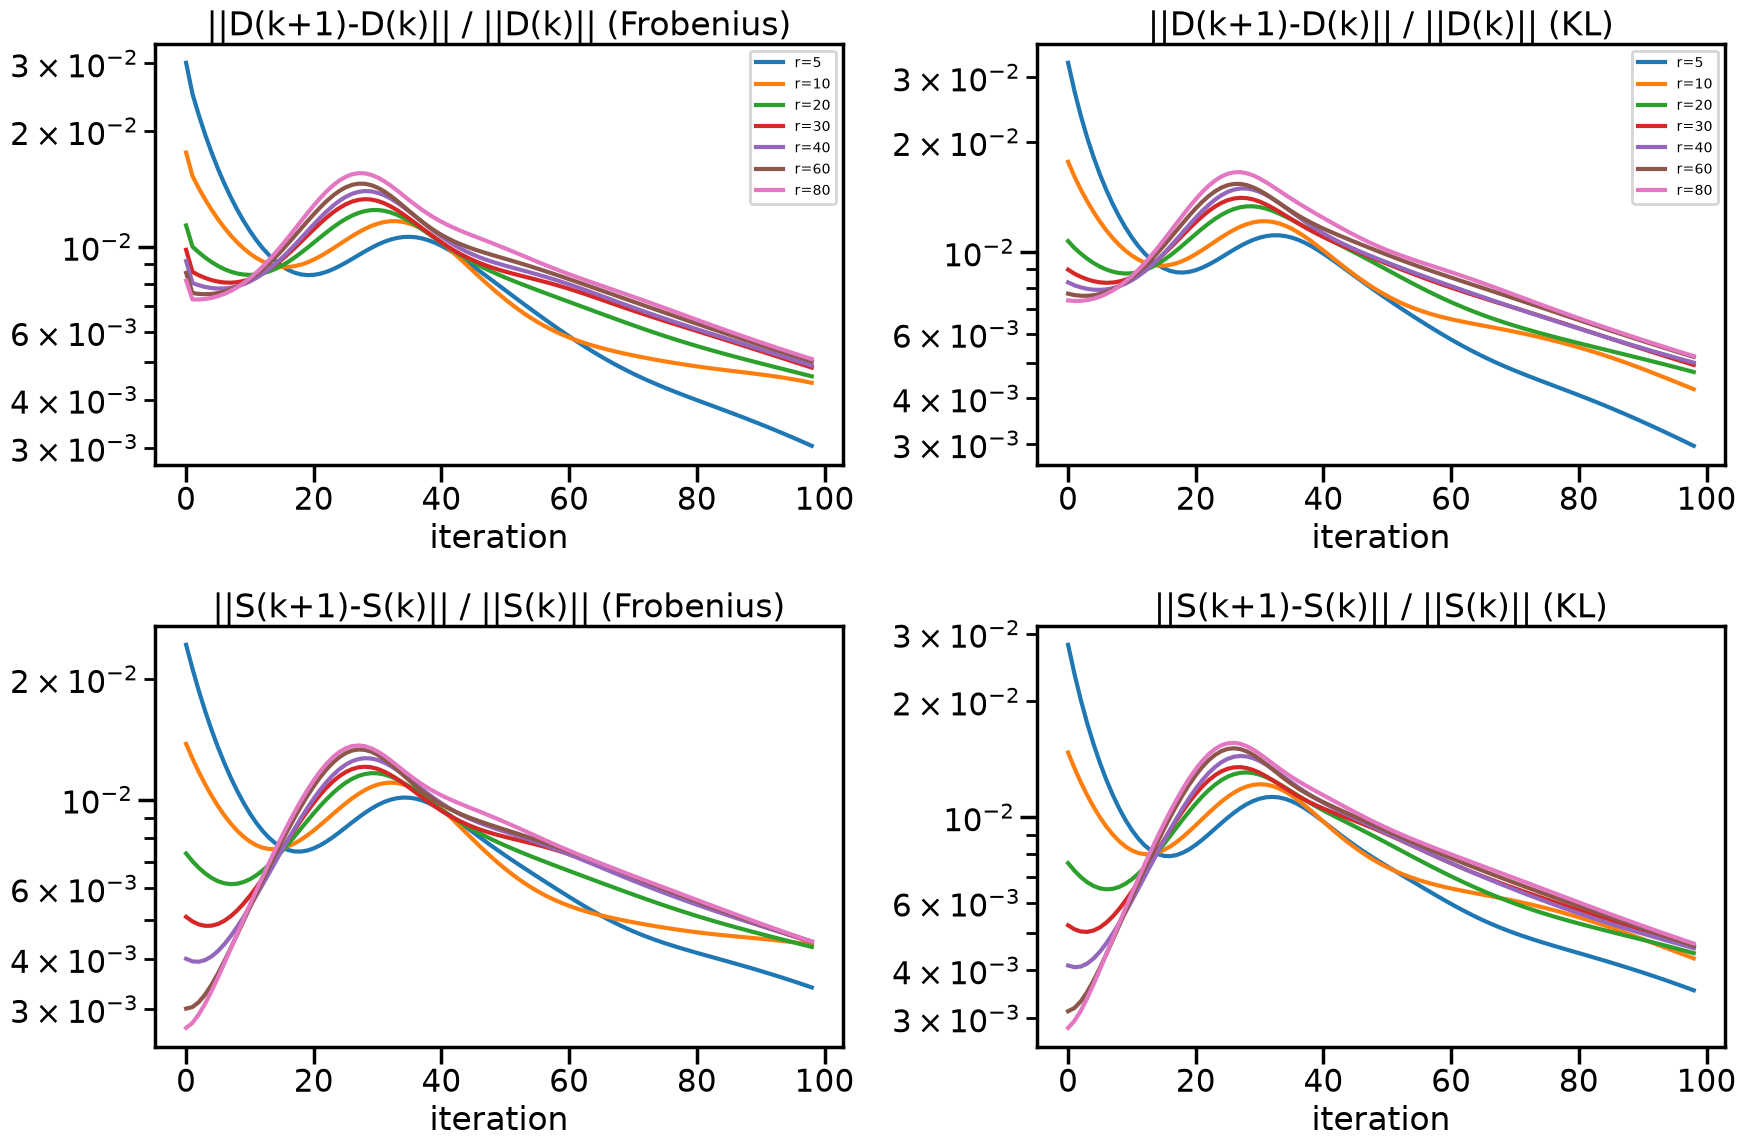

In [8]:
#TODO : plot the loss and normalized distances between S and D for different number of components, for the Frobenius distance AND KL divergence
#Compare and discuss
number_of_components = [5, 10, 20, 30, 40, 60, 80]
n_epochs = 100
errors = {"Frobenius": {}, "KL": {}}
dist_D = {"Frobenius": {}, "KL": {}}
dist_S = {"Frobenius": {}, "KL": {}}

for loss in ["Frobenius", "KL"]:
    for r in number_of_components:
        model = MYNMF(n_components=r, max_iter=n_epochs, epsilon = 1e-5, loss=loss, random_state=42)
        model.fit_transform(train, mu=5e-3, nu=5e-3, lambd=1e-3)
        # NB : transform utilise nnls (projection moindres carrés), y compris pour le modèle KL
        reconstructed = model.D_ @ model.transform(test)
        errors[loss][r] = frob_err(test, reconstructed) if loss == "Frobenius" else kl_div(test, reconstructed)
        # distance normalisée entre deux itérés successifs (convergence de l'algorithme)
        Dh, Sh = model.D_history, model.S_history
        dist_D[loss][r] = [np.linalg.norm(Dh[k+1] - Dh[k]) / np.linalg.norm(Dh[k]) for k in range(n_epochs - 1)]
        dist_S[loss][r] = [np.linalg.norm(Sh[k+1] - Sh[k]) / np.linalg.norm(Sh[k]) for k in range(n_epochs - 1)]

# les deux erreurs n'ont pas la même échelle : un graphique chacune
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, loss in zip(axes, ["Frobenius", "KL"]):
    ax.plot(list(errors[loss].keys()), list(errors[loss].values()), marker='o')
    ax.set(title=f'Test error vs r ({loss})', xlabel='Number of components', ylabel='Error')
fig.tight_layout()

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for j, loss in enumerate(["Frobenius", "KL"]):
    for r in number_of_components:
        axes[0, j].semilogy(dist_D[loss][r], label=f'r={r}')
        axes[1, j].semilogy(dist_S[loss][r], label=f'r={r}')
    axes[0, j].set(title=f'||D(k+1)-D(k)|| / ||D(k)|| ({loss})', xlabel='iteration')
    axes[1, j].set(title=f'||S(k+1)-S(k)|| / ||S(k)|| ({loss})', xlabel='iteration')
    axes[0, j].legend(fontsize=10)
fig.tight_layout()

## Model training

In [9]:
#TODO : Train different models for different number of components with Frobenius loss AND KL divergence, and plot loss function 

## First application

For the first application you are going to analyse the face data to give an interpretation of the factorization:

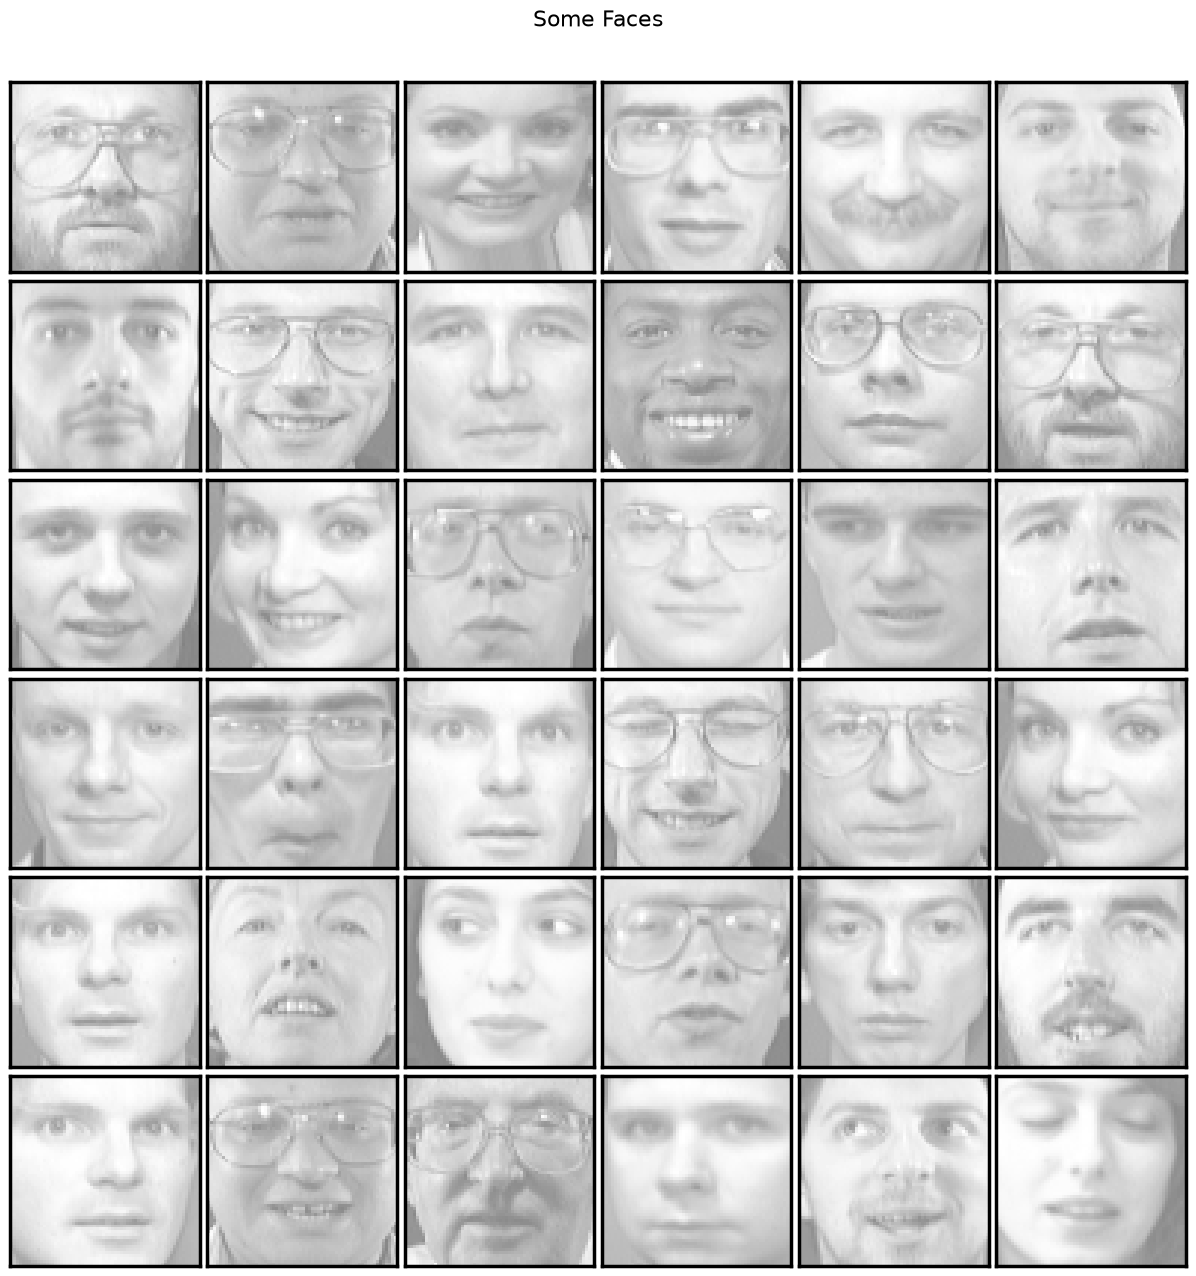

In [18]:
faces = faces.T  # n = 400 flattened images of p = 4096 = 64 x 64 pixels
image_shape = (64, 64)
n_samples, n_features = faces.shape

# global centering
faces_centered = faces - faces.mean(axis=0)

# local centering
faces_centered -= faces_centered.mean(axis=1).reshape(n_samples, -1)

def plot_gallery(images, image_shape, nrow, ncol, title='', cmap=plt.cm.gray, nonneg=False):
    
    # fit the nb of images into a square
    n_images = len(images)
    nrows = nrow
    ncols = ncol
    
    # instantiate figure
    fig, axes = plt.subplots(nrows, ncols, figsize=(2. * ncols, 2.26 * nrows))
    fig.suptitle(title, size=16)
    
    axes_for_display = axes.flatten()[:n_images]
    axes_to_blank = axes.flatten()[n_images:]
    
    for idx, comp in enumerate(images):
        ax = axes_for_display[idx]
        vmax = max(comp.max(), -comp.min())
        vmin = 0 if nonneg else -vmax  # images non négatives (NMF) : 0 = noir au lieu de gris
        ax.imshow(comp.reshape(image_shape), cmap=cmap,
                   interpolation='nearest',
                   vmin=vmin, vmax=vmax)
        ax.set(xticks=(),
               yticks=())
        
    for ax in axes_to_blank:
        ax.axis('off')

    fig.tight_layout()
    fig.subplots_adjust(0.01, 0.05, 0.99, 0.93, 0.04, 0.)  # insert space below the suptitle
    
plot_gallery(title="Some Faces", 
             images=faces[:36], 
             image_shape=image_shape,nrow=6,ncol=6)

### Analysis of the number of components on the reconstruction

#### Reconstruction with Frobenius distance

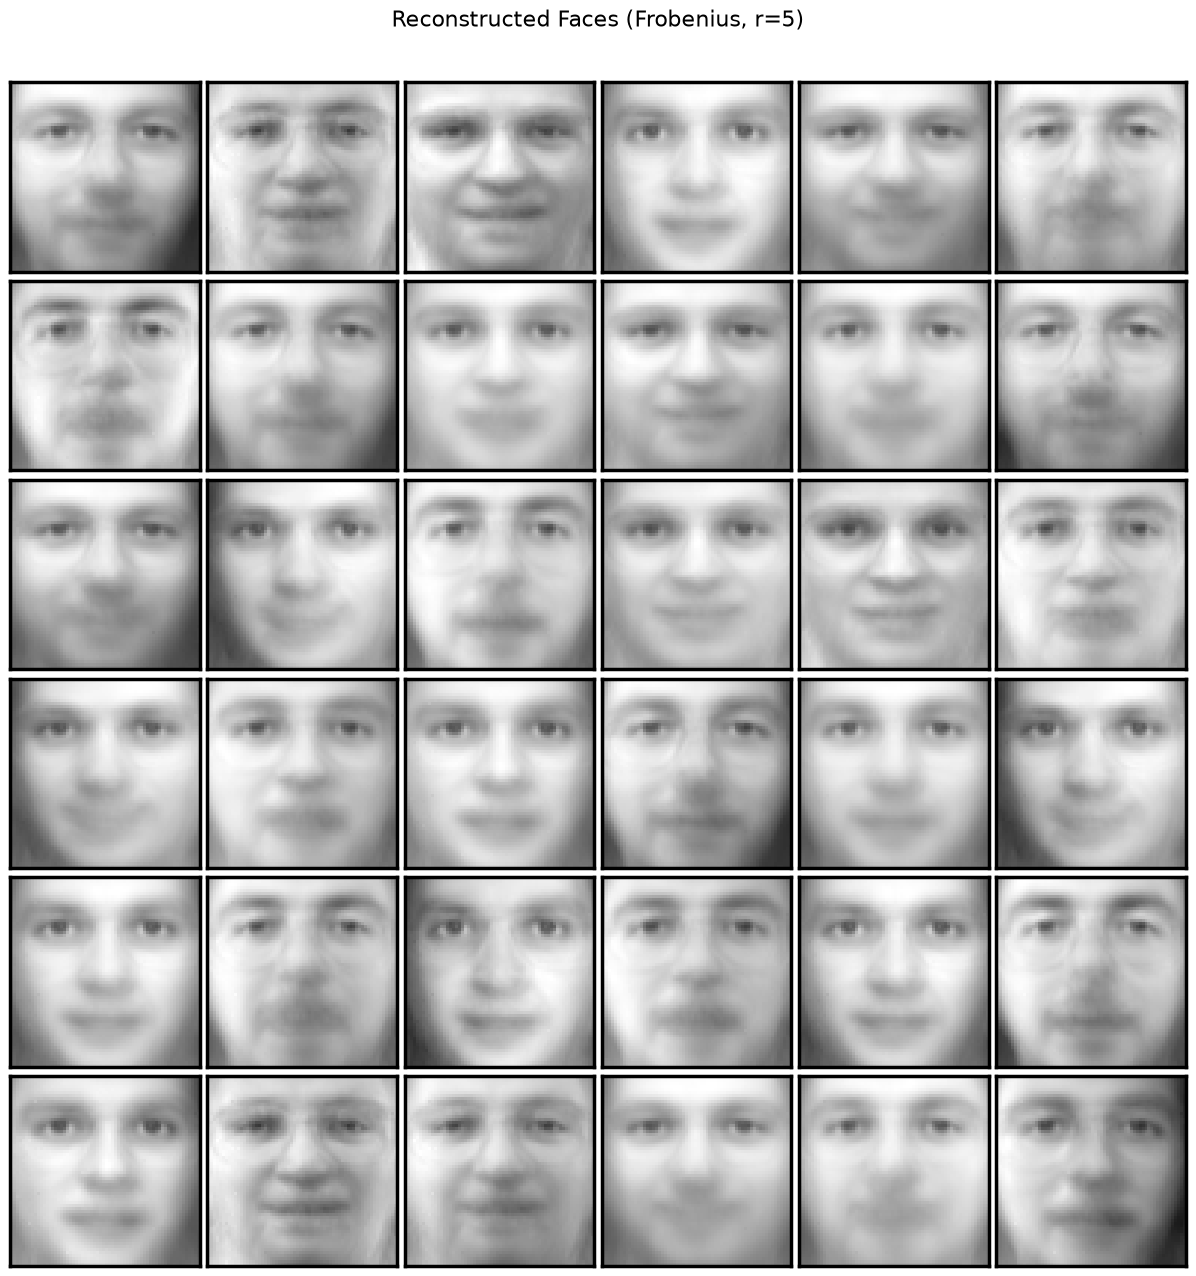

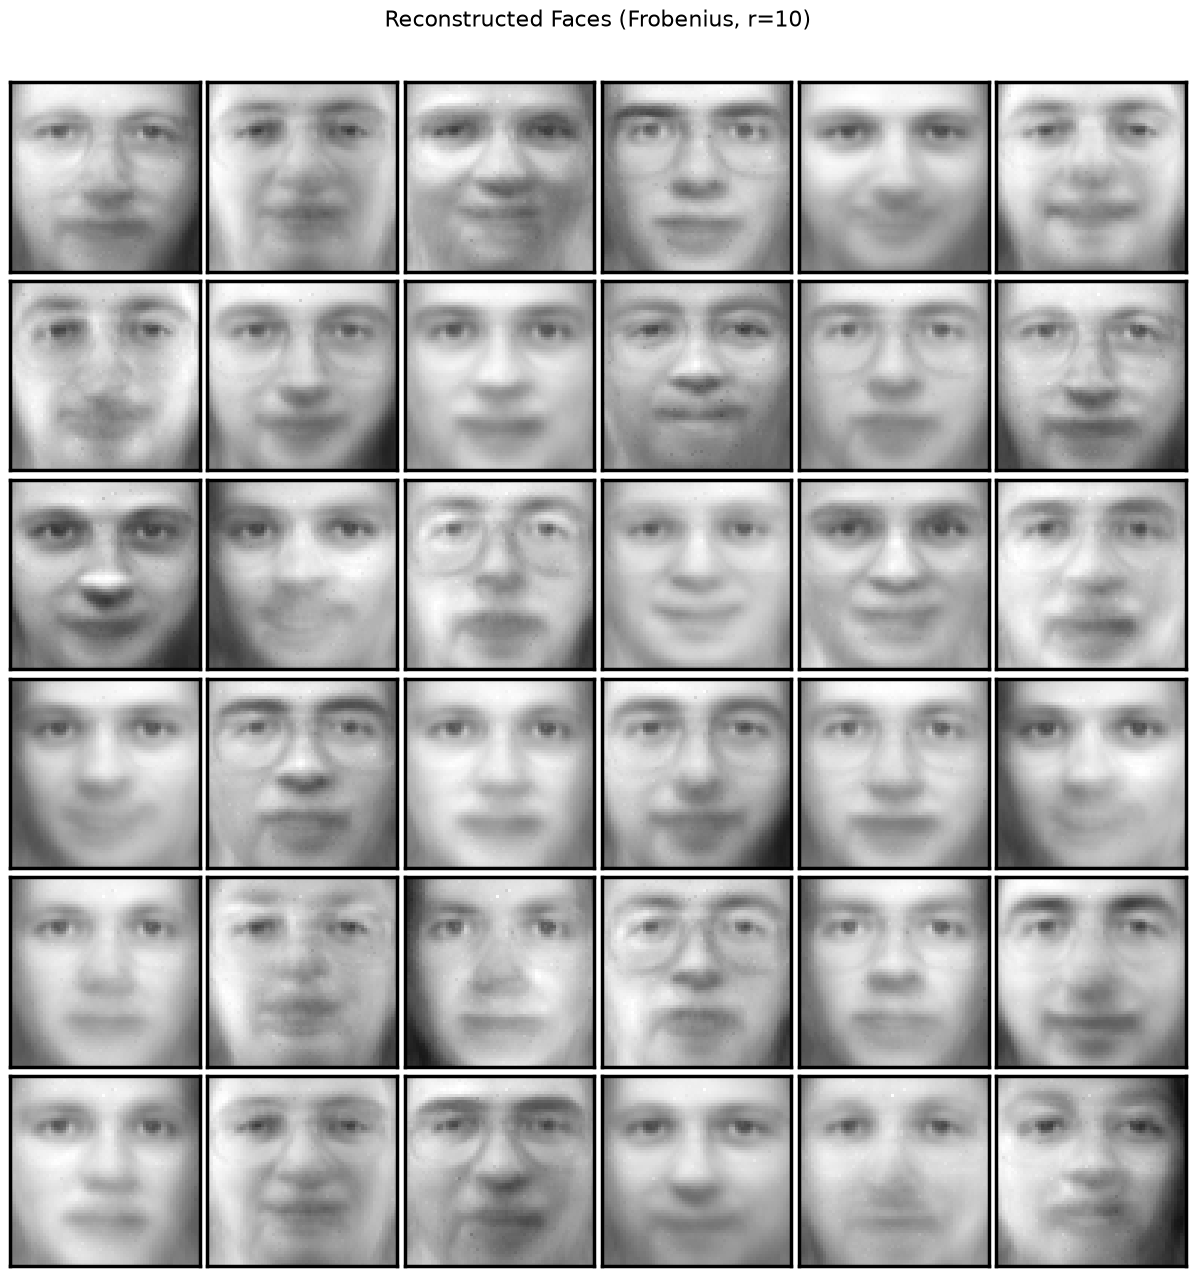

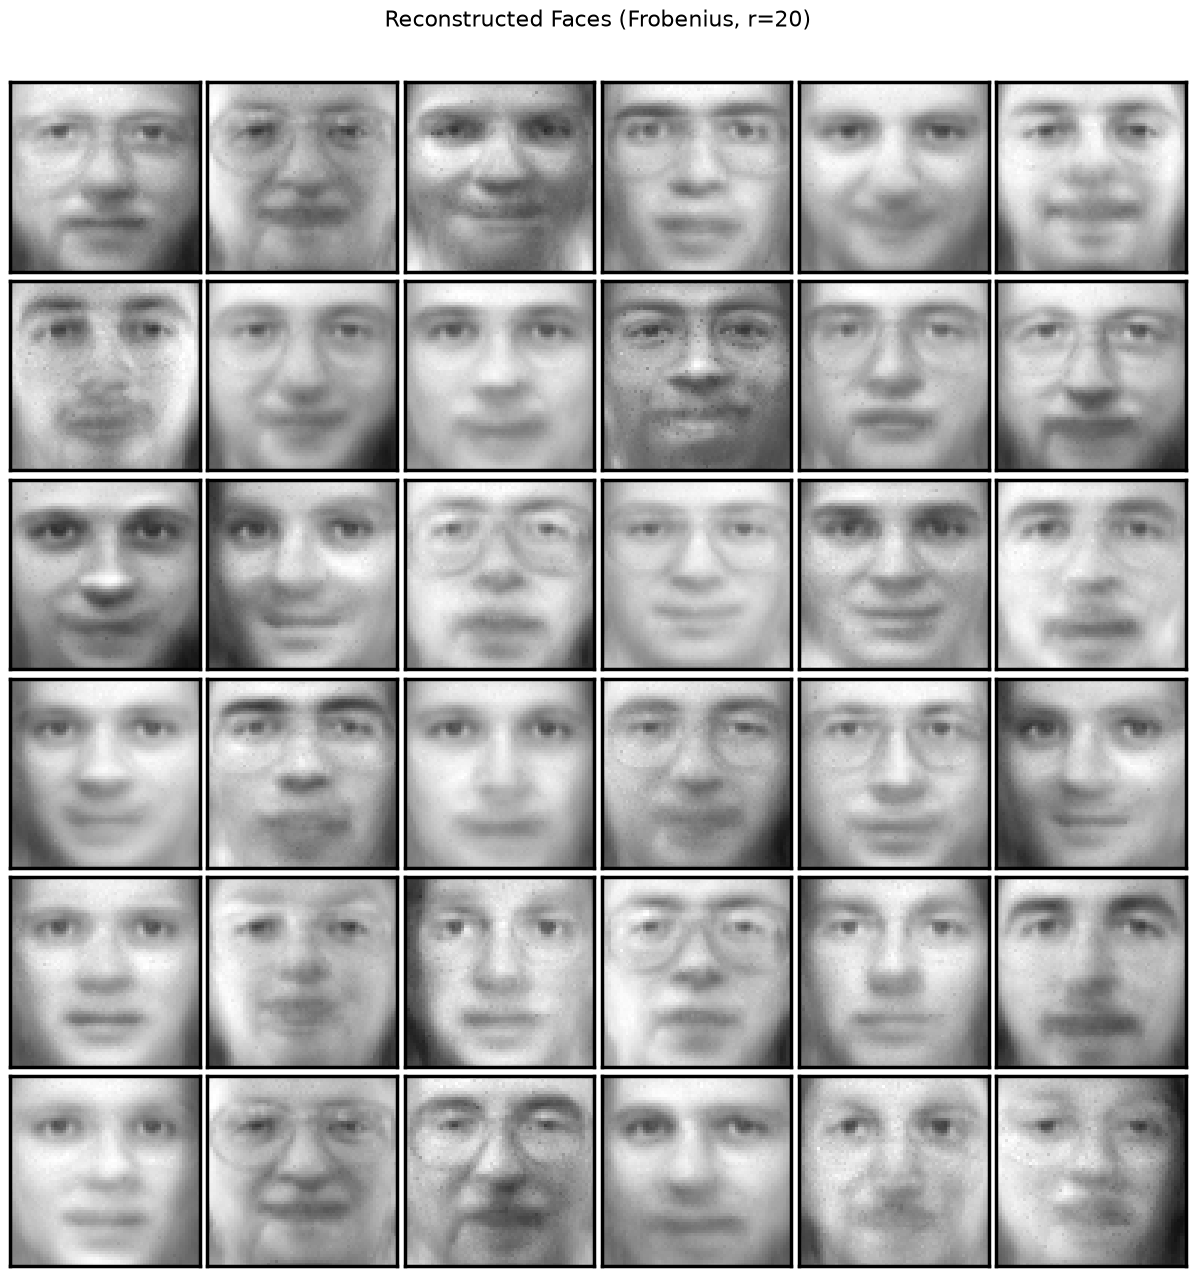

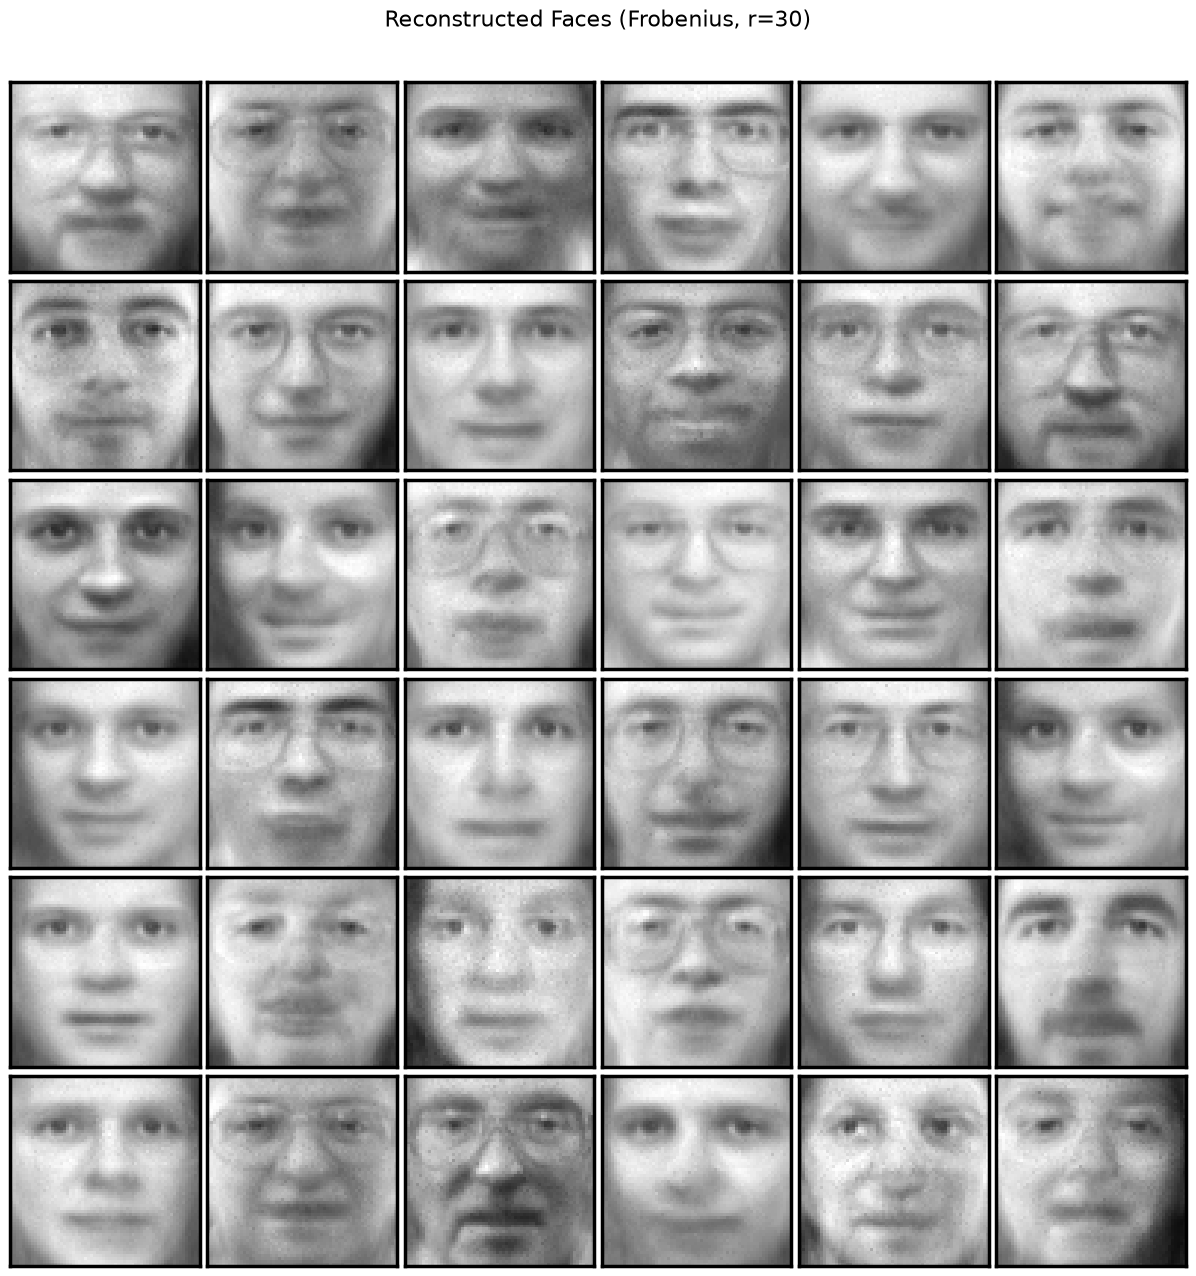

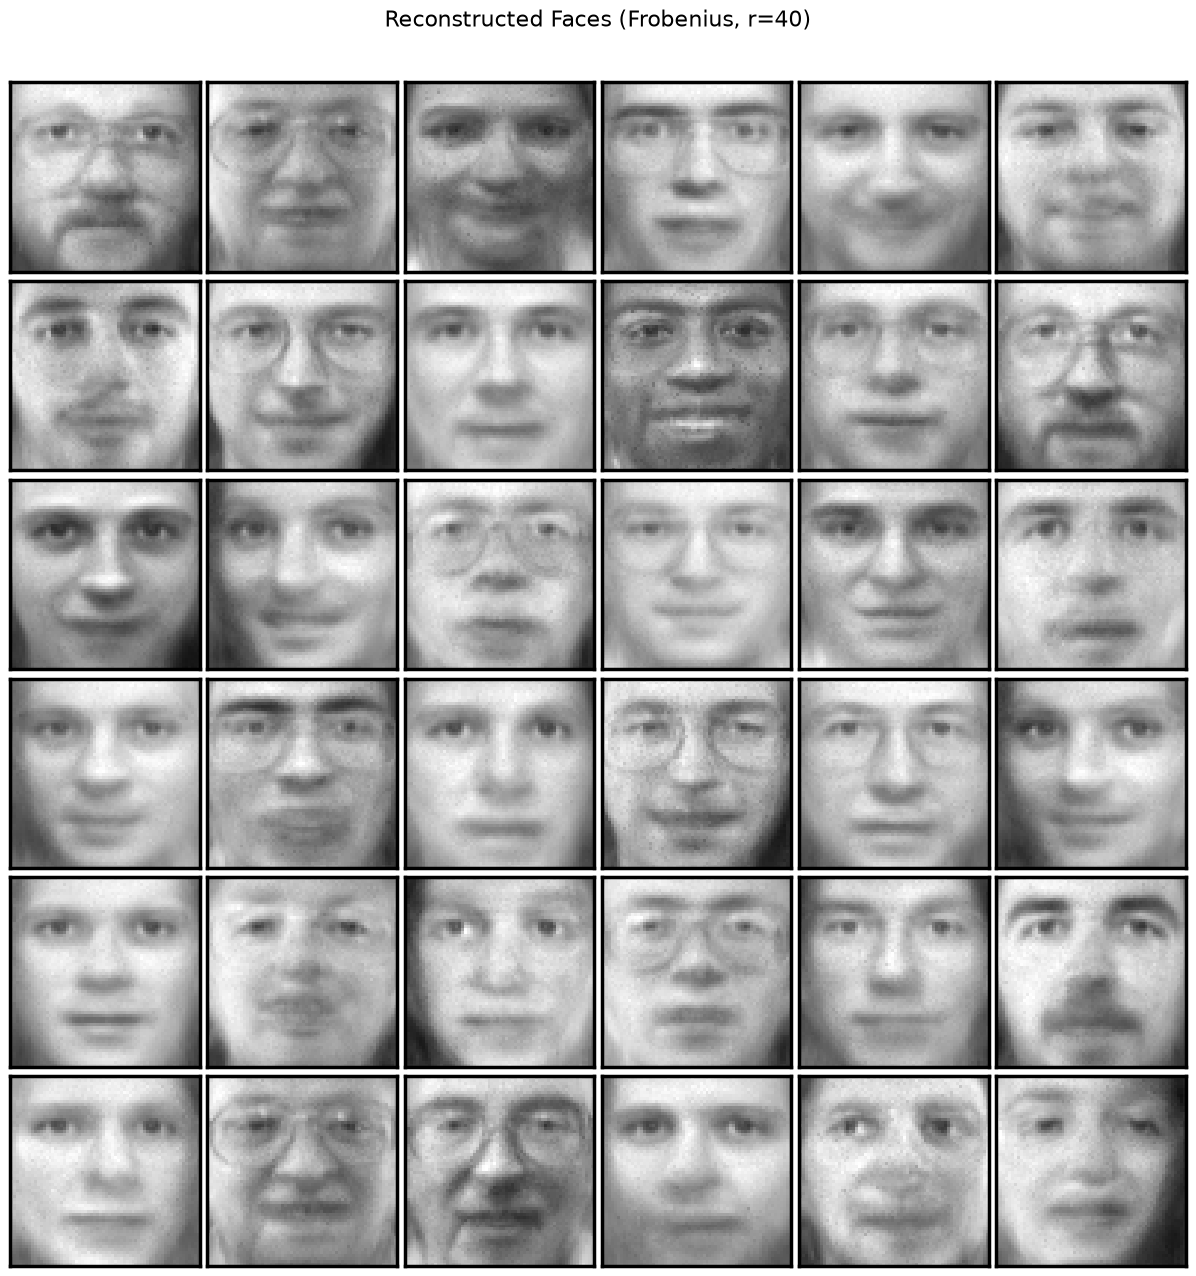

In [19]:
#TODO : plot reconstructed faces for different number of components with Frobenius distance
list_components = [5, 10, 20, 30, 40]
atoms = {}  # (loss, r) -> D, réutilisé pour tracer les atomes du dictionnaire

def reconstruct_faces(n_components, loss="Frobenius"):
    # NMF needs non-negative data: use the raw faces, not faces_centered
    model = MYNMF(n_components=n_components, max_iter=200, epsilon=1e-5, loss=loss, random_state=42)
    model.fit_transform(faces.T, mu=5e-3, nu=5e-3, lambd=1e-3)   # data is (p, n)
    reconstructed_faces = model.D_ @ model.S_                    # (p, n), no need to re-solve with nnls
    plot_gallery(title=f"Reconstructed Faces ({loss}, r={n_components})",
                 images=reconstructed_faces.T[:36],
                 image_shape=image_shape, nrow=6, ncol=6, nonneg=True)
    atoms[(loss, n_components)] = model.D_
    return model

for n_components in list_components:
    reconstruct_faces(n_components)

#### Reconstruction with Kullback-Leibler divergence

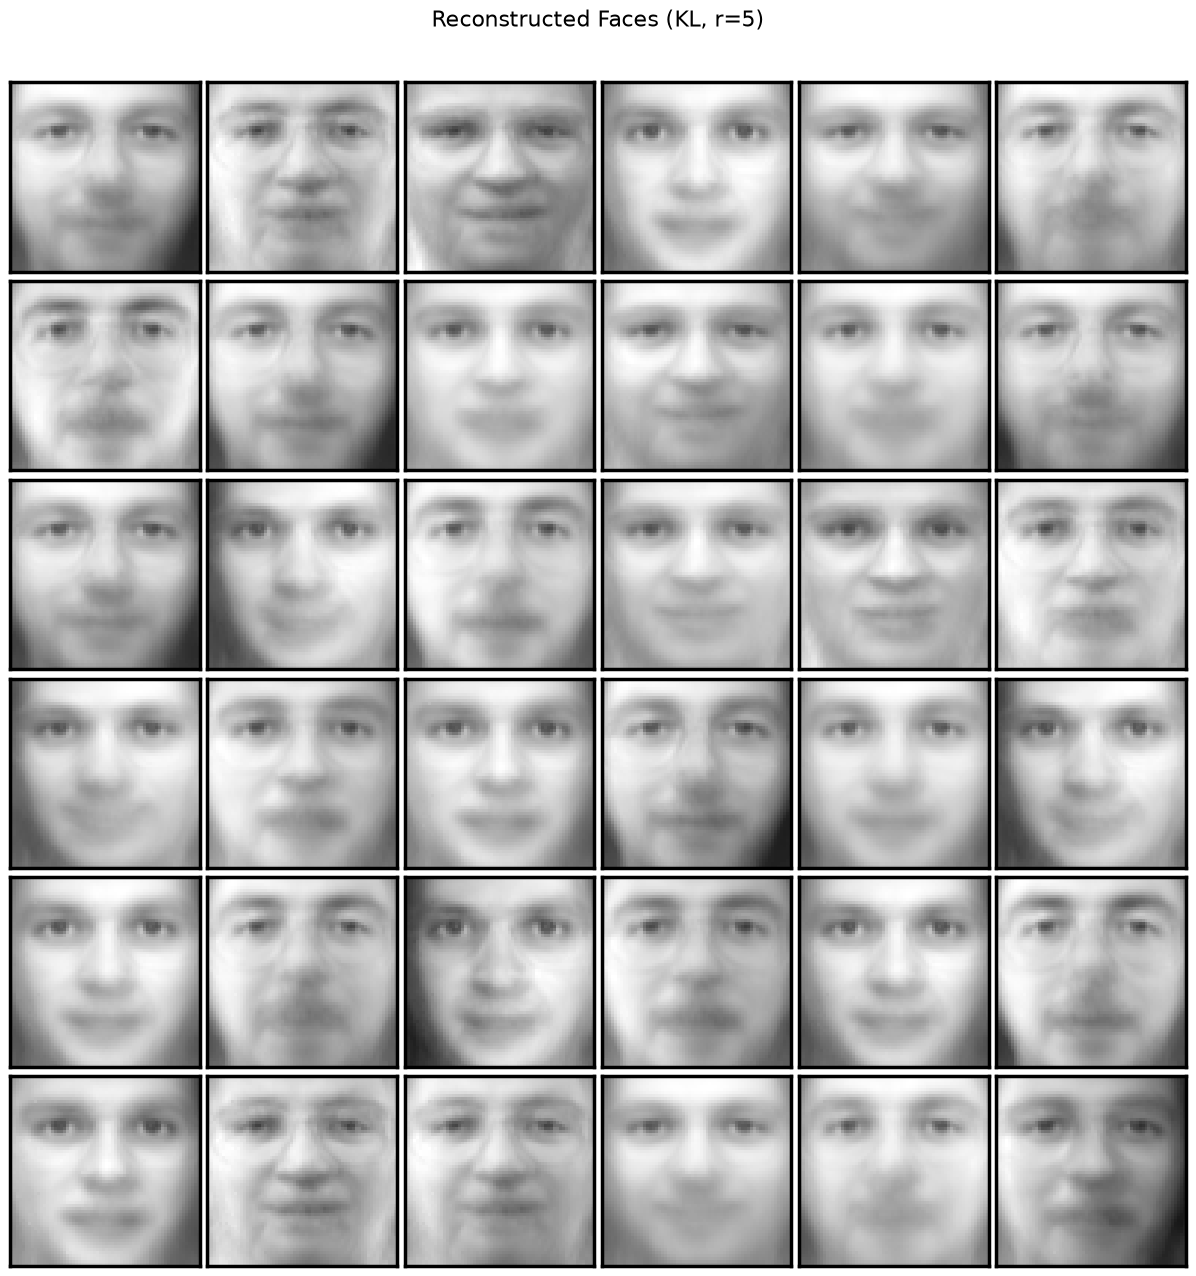

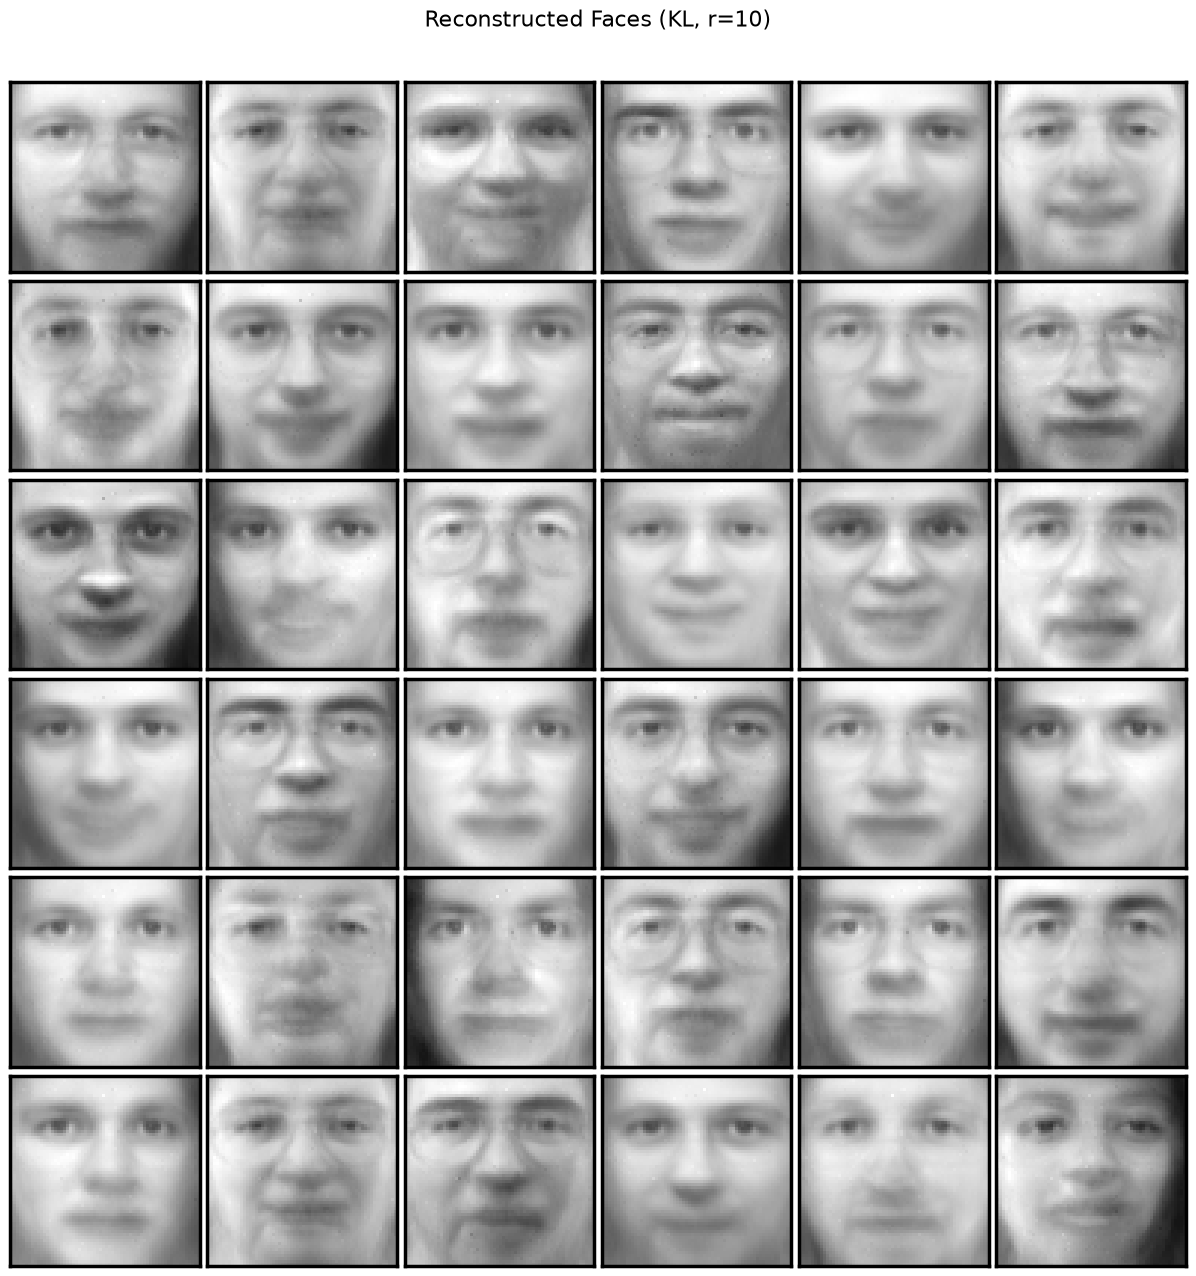

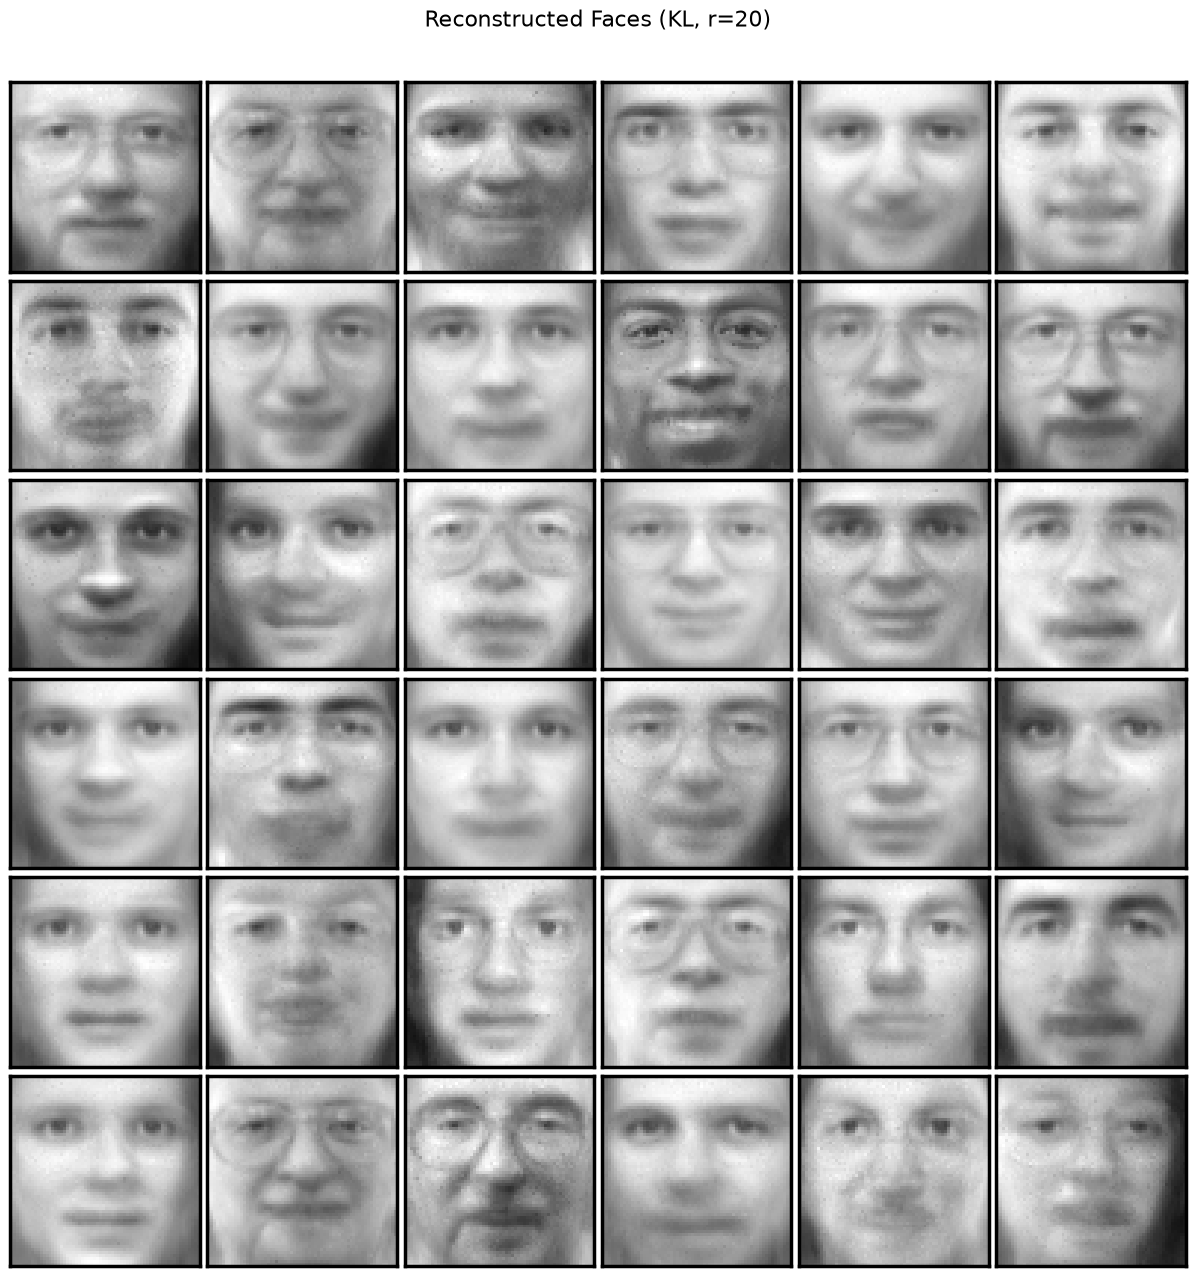

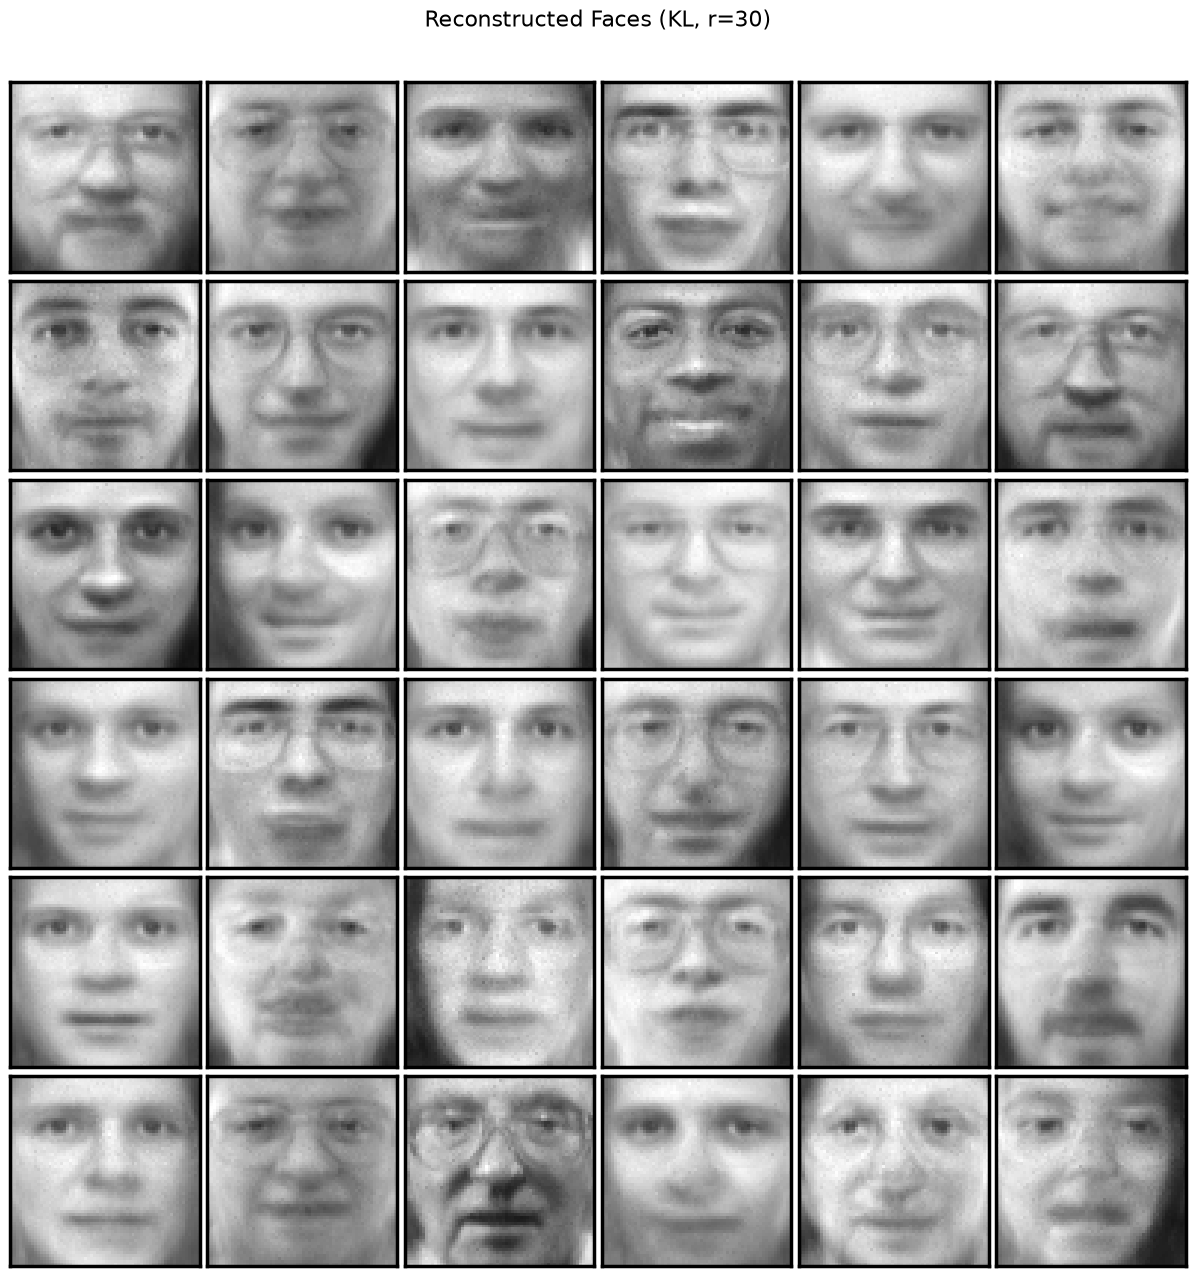

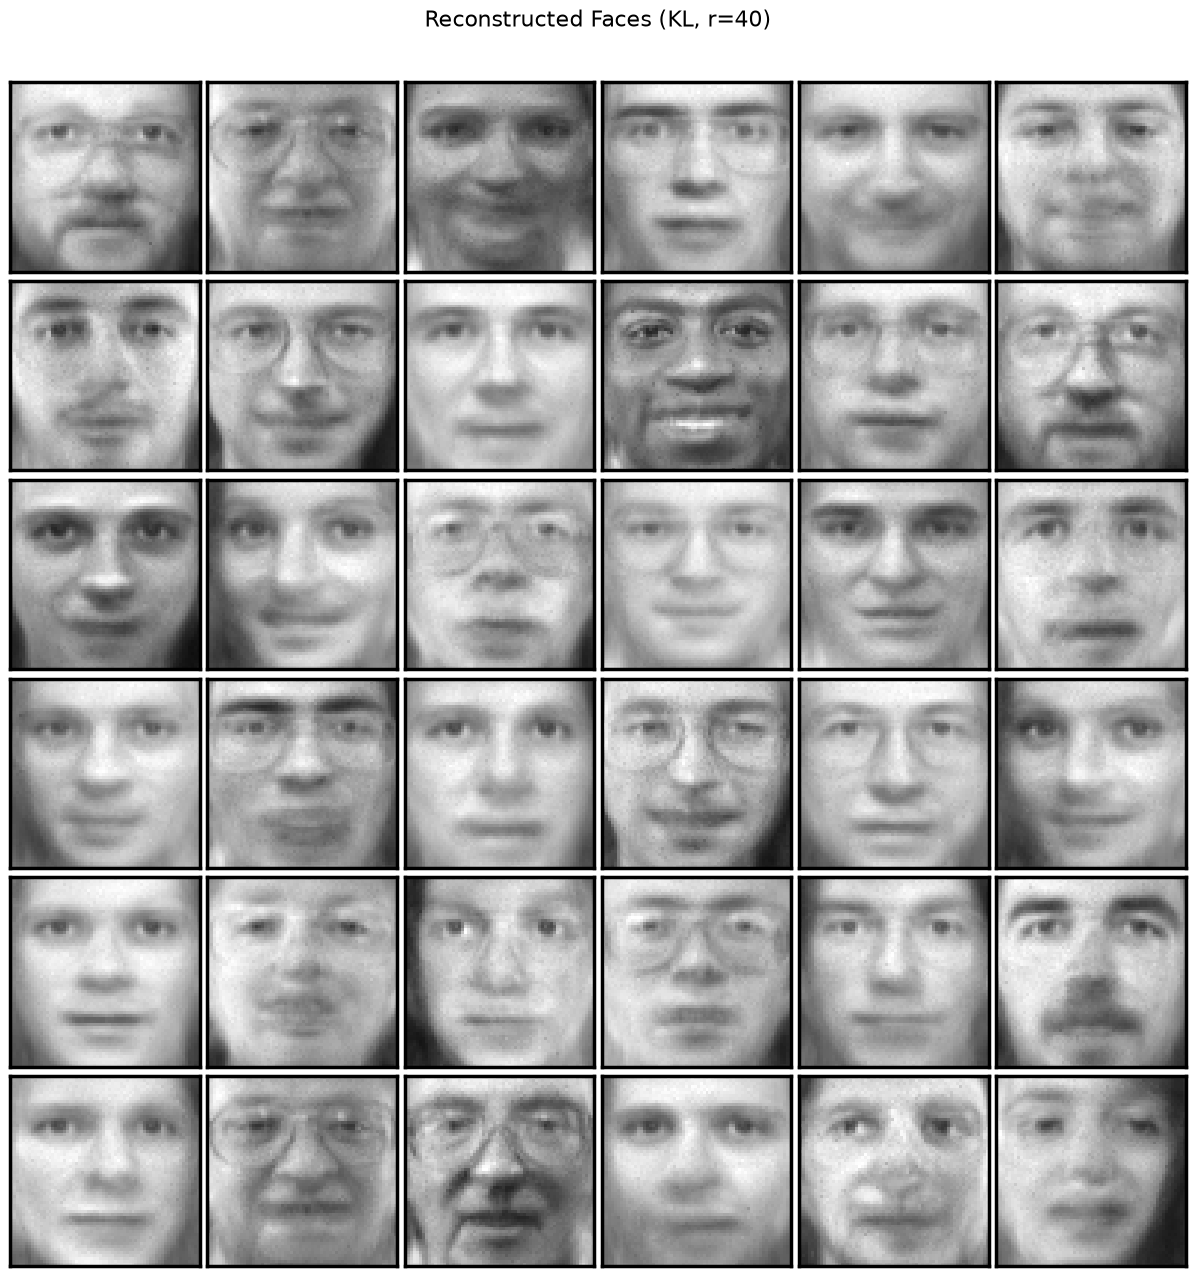

In [20]:
#TODO : plot reconstructed faces for different number of components with KL divergence
for n_components in list_components:
    reconstruct_faces(n_components, loss="KL")

#### Comparison of the elements of the dictionary between the two distances

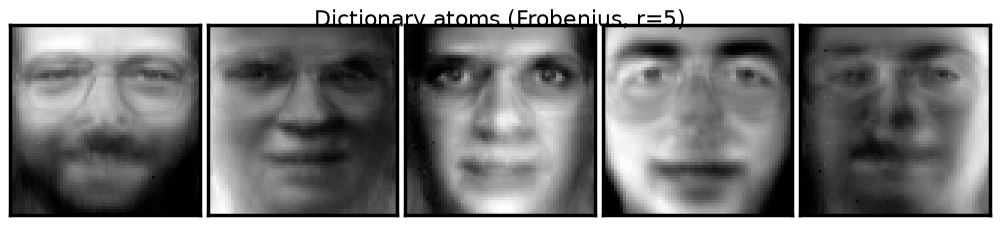

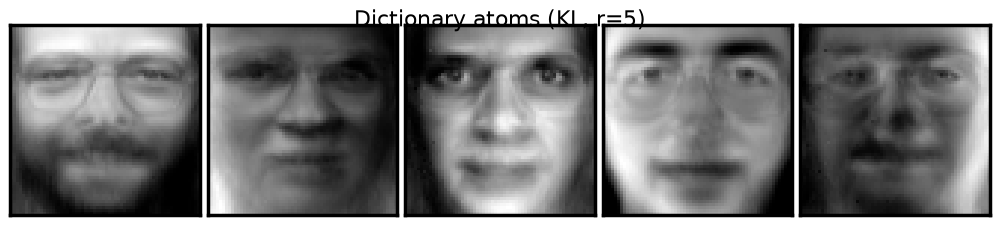

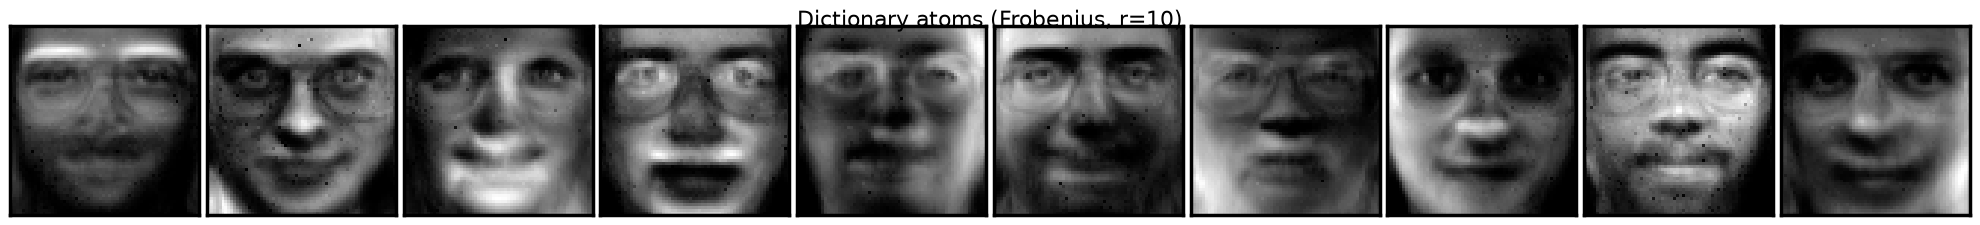

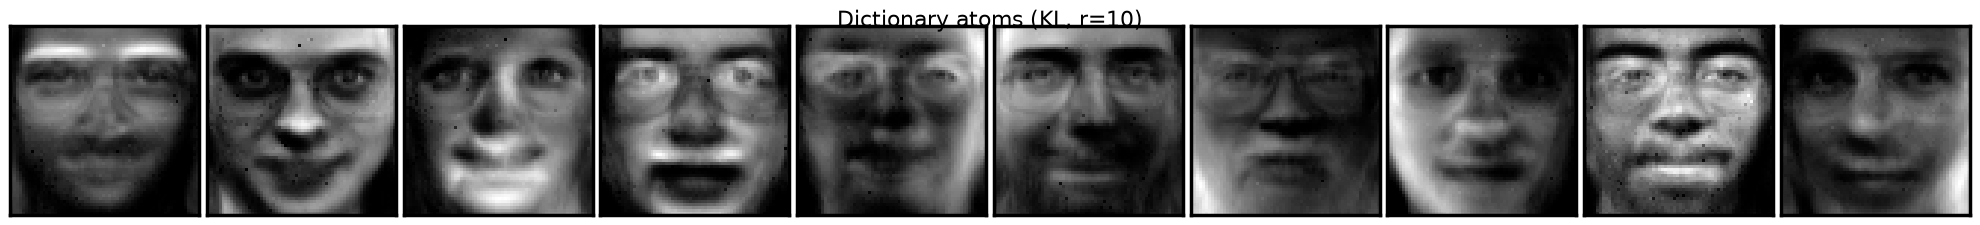

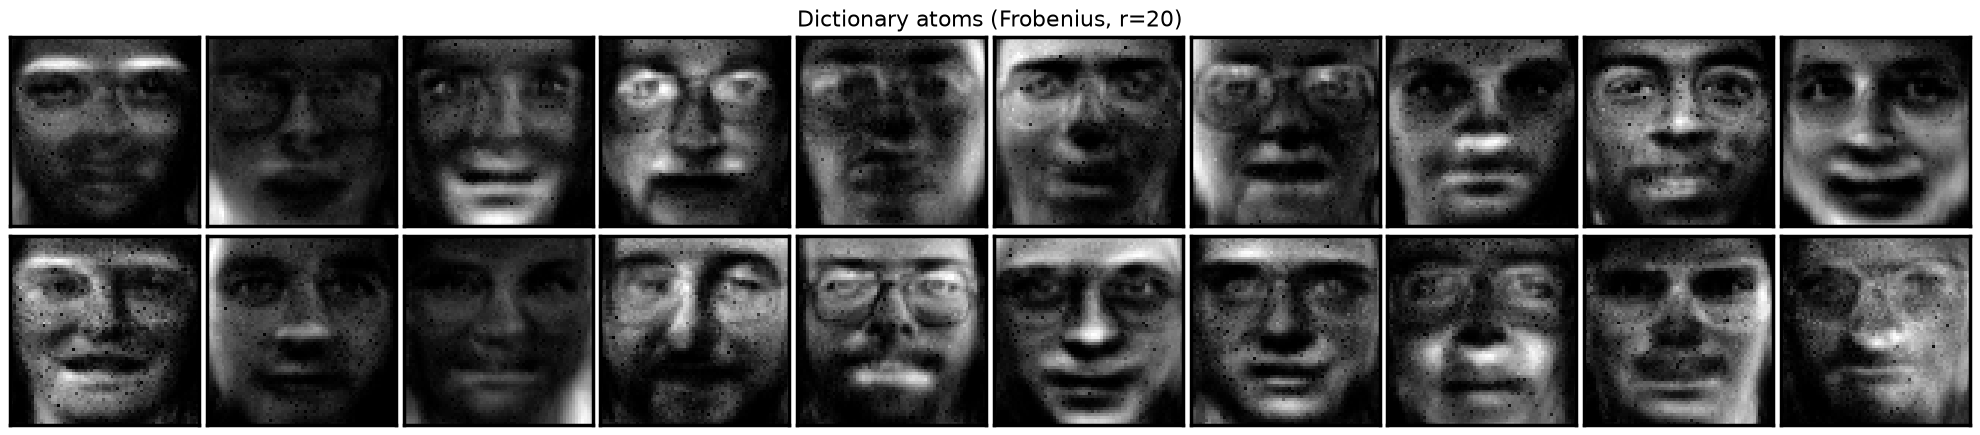

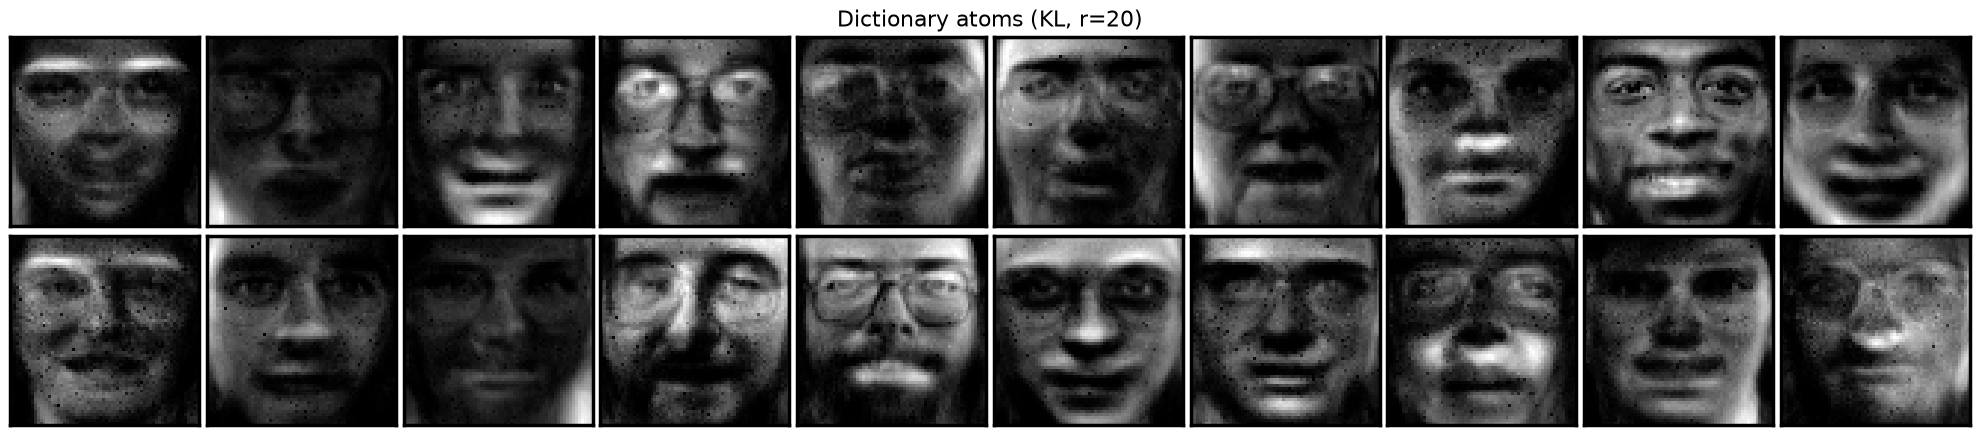

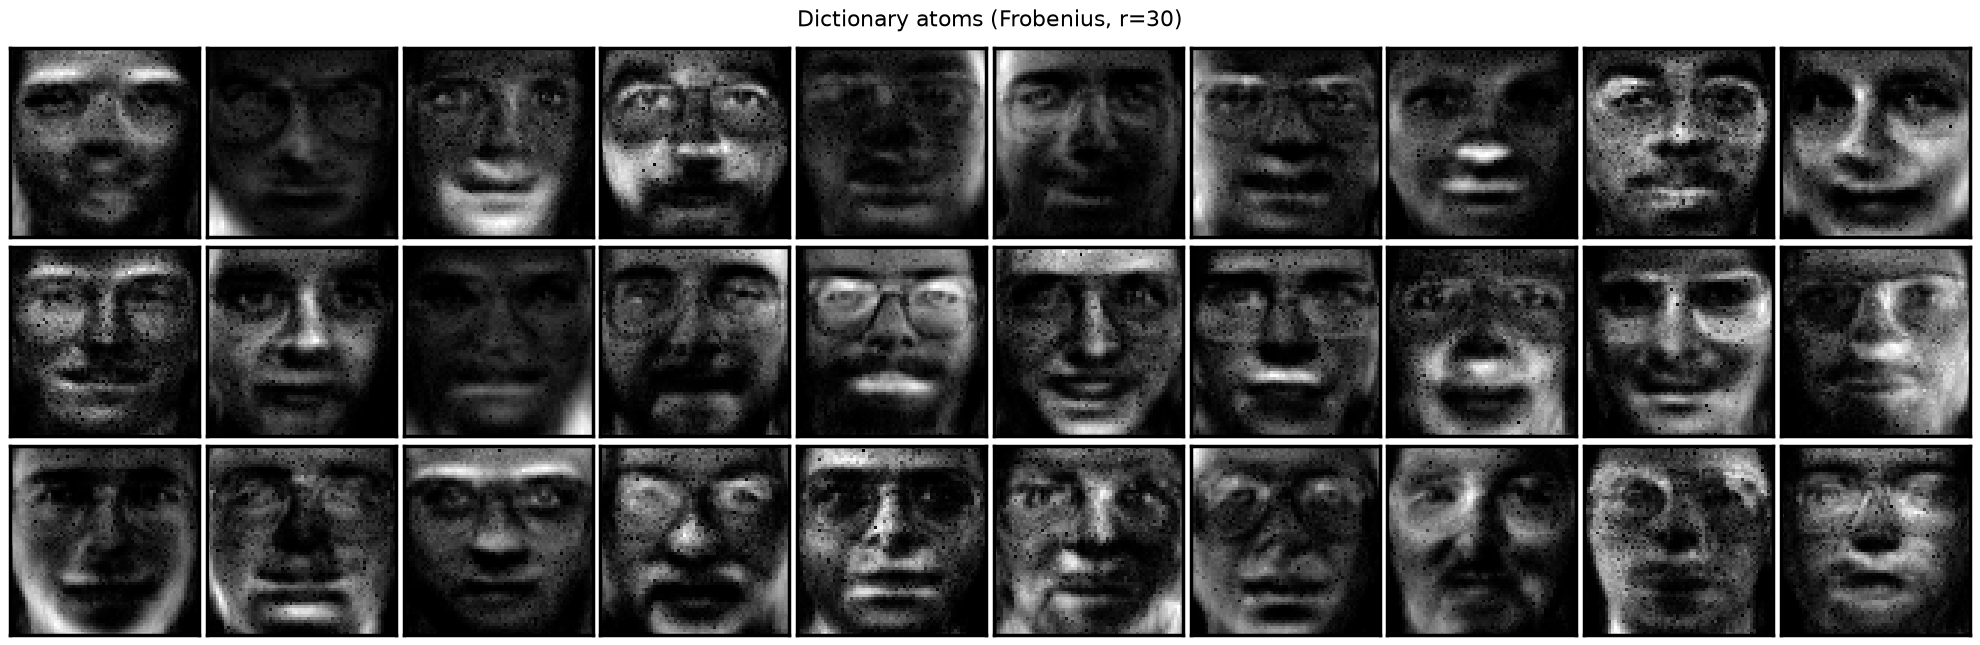

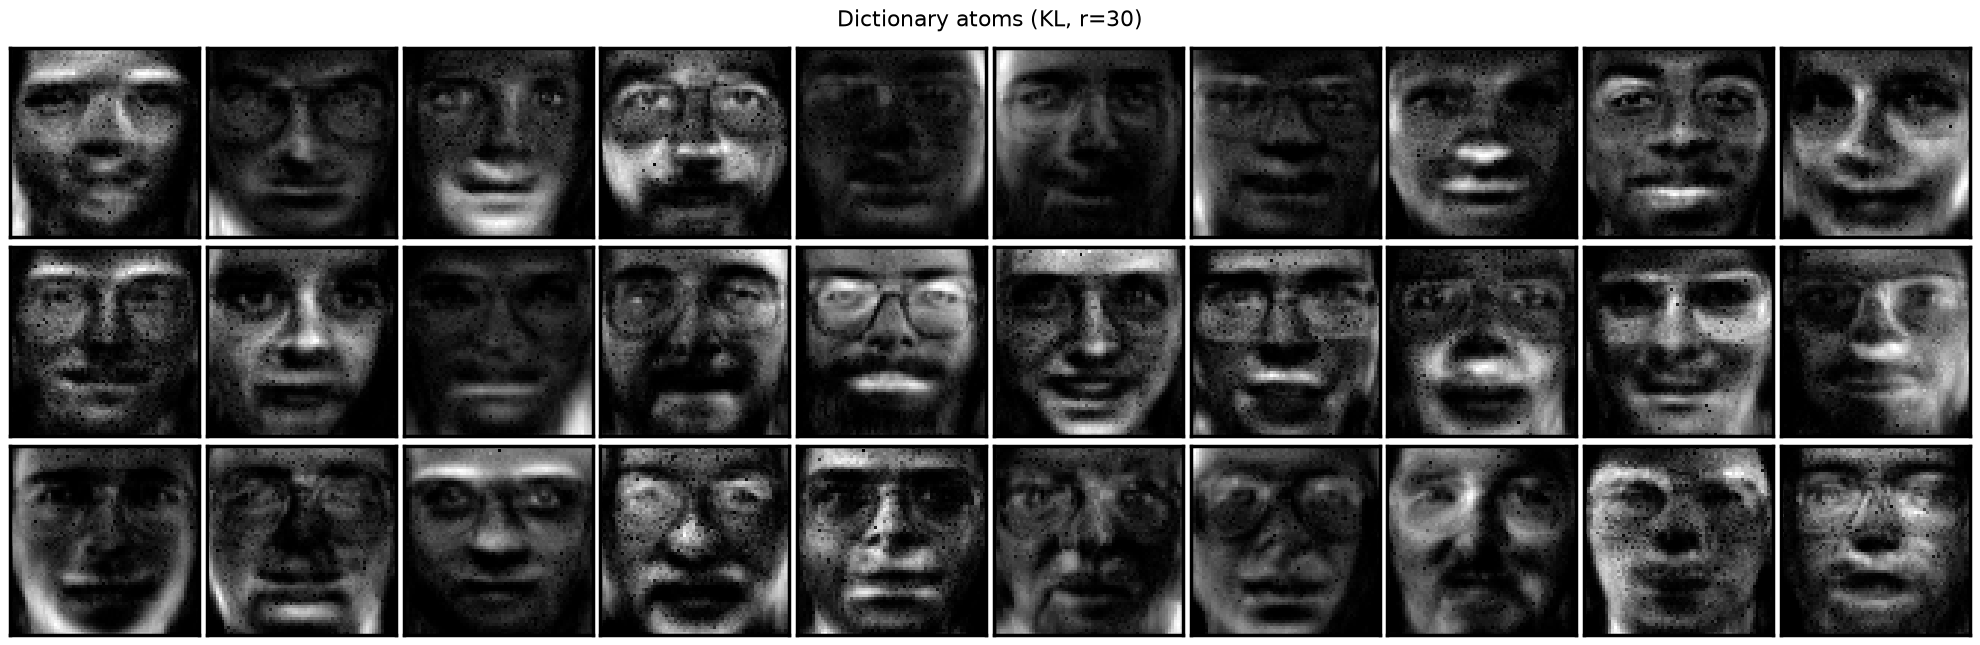

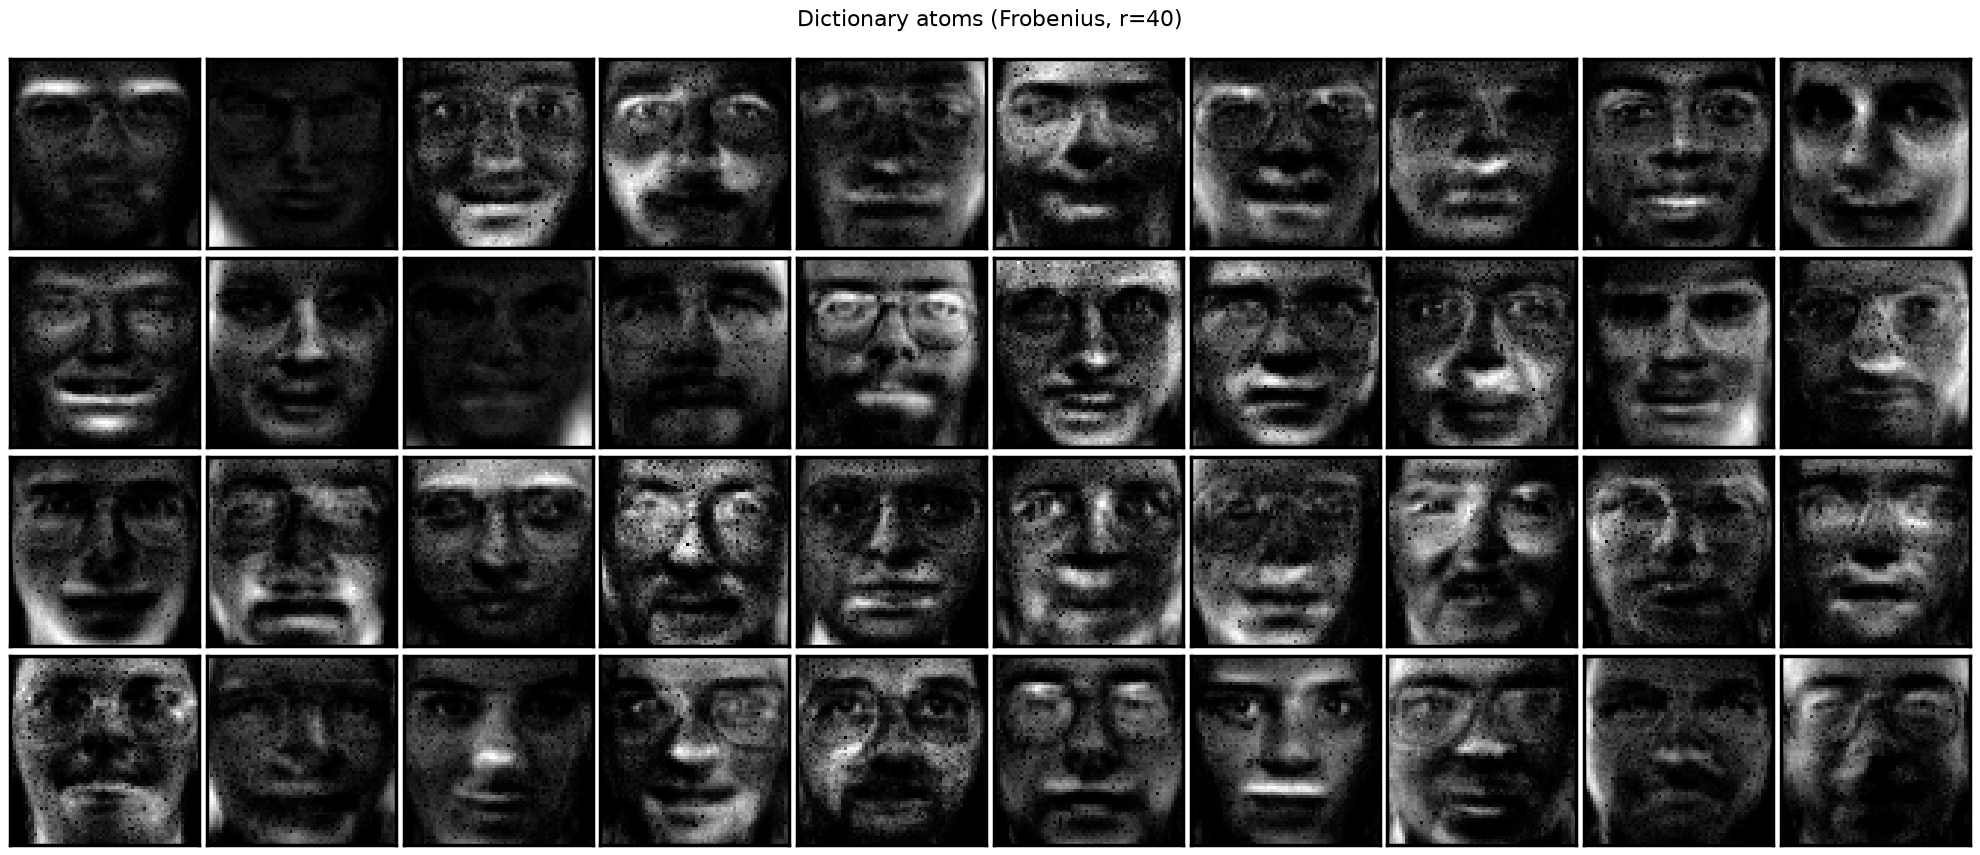

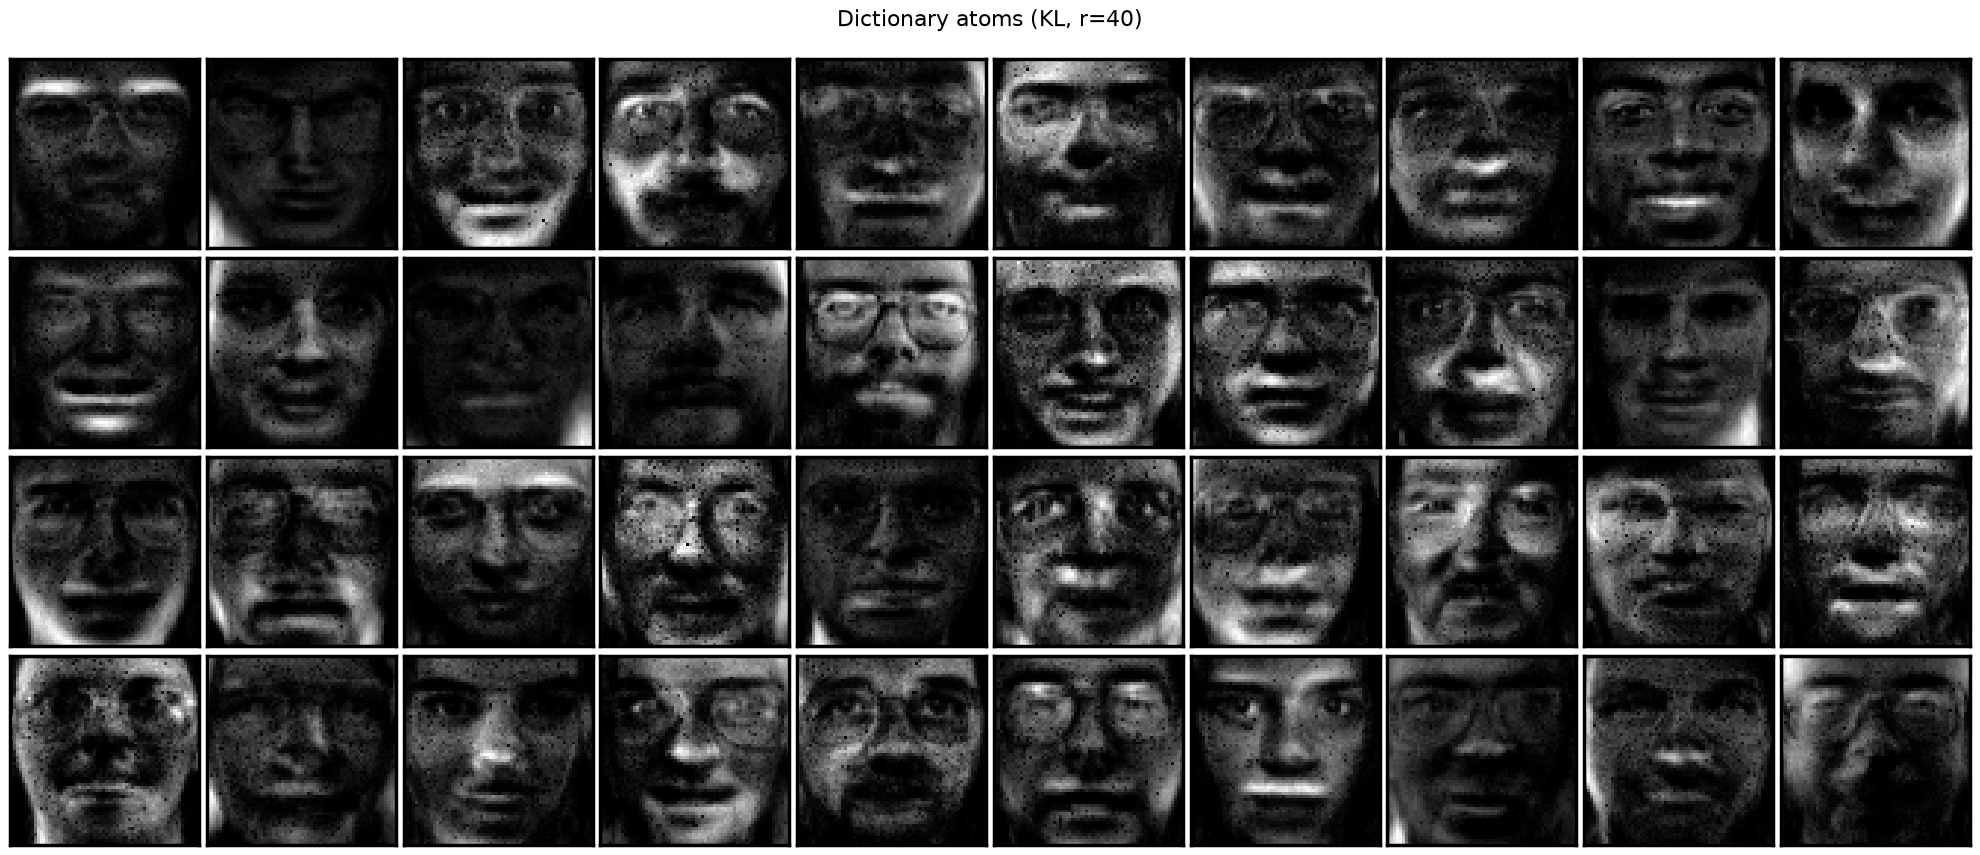

In [21]:
#TODO : plot the atoms of the dictionary for various number of components
# les atomes sont les colonnes de D (p, r) : on trace les lignes de D.T, chacune une image 64x64
# (dictionnaires calculés dans les cellules de reconstruction Frobenius et KL ci-dessus)
def plot_atoms(D, title):
    r = D.shape[1]
    ncol = min(r, 10)
    nrow = int(np.ceil(r / ncol))
    plot_gallery(title=title, images=D.T, image_shape=image_shape,
                 nrow=nrow, ncol=ncol, nonneg=True)

for n_components in list_components:
    for loss in ["Frobenius", "KL"]:
        plot_atoms(atoms[(loss, n_components)], f"Dictionary atoms ({loss}, r={n_components})")

### Study of the clustering for the Frobenius distance with 30 components

Now, we are going to clusterise the images in r different classes. First, we start by normalizing the norm of the dictionary elements, so that the euclidian norm = 1, and we multiply the associated row in the S matrix to preserve the factorization DS = X. Then, we find the highest coefficient for each image, and we use the index of the maximum as clustering label.

In [ ]:
#TODO : Study the clustering
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics.cluster import contingency_matrix

r = 30
model = MYNMF(n_components=r, max_iter=200, epsilon = 1e-5, loss = "Frobenius", random_state=42)
model.fit_transform(faces.T, mu=5e-3, nu=5e-3, lambd=1e-3)
dictionary_atoms = model.D_
atom_norms = np.linalg.norm(dictionary_atoms, axis=0, keepdims=True)  # (1, r)
normalized_dictionary_atoms = dictionary_atoms / atom_norms
new_S = model.S_ * atom_norms.T  # on multiplie les lignes de S pour garder D S = X, les coefficients deviennent comparables
assert np.allclose(normalized_dictionary_atoms @ new_S, model.D_ @ model.S_)
highest_coeff_indices = np.argmax(new_S, axis=0)  # pour chaque image, l'indice de l'atome le plus fort = label du cluster

# taille des clusters : certains atomes ne sont jamais dominants (clusters vides)
cluster_sizes = np.bincount(highest_coeff_indices, minlength=r)
print(f"Clusters non vides : {np.sum(cluster_sizes > 0)} / {r}")
plt.figure(figsize=(14, 5))
plt.bar(np.arange(r), cluster_sizes)
plt.title('Cluster sizes (NMF Frobenius, r=30)')
plt.xlabel('Cluster (atom index)')
plt.ylabel('Number of images')

# pour les clusters les plus peuplés : l'atome (1re colonne) puis quelques images du cluster
n_show_clusters, n_show_images = 8, 6
top_clusters = np.argsort(cluster_sizes)[::-1][:n_show_clusters]
fig, axes = plt.subplots(n_show_clusters, n_show_images + 1, figsize=(2 * (n_show_images + 1), 2.2 * n_show_clusters))
for row, k in enumerate(top_clusters):
    axes[row, 0].imshow(normalized_dictionary_atoms[:, k].reshape(image_shape), cmap=plt.cm.gray)
    axes[row, 0].set_title(f'atom {k} ({cluster_sizes[k]})', fontsize=12)
    members = np.where(highest_coeff_indices == k)[0][:n_show_images]
    for col in range(n_show_images):
        if col < len(members):
            axes[row, col + 1].imshow(faces[members[col]].reshape(image_shape), cmap=plt.cm.gray)
        axes[row, col + 1].axis('off')
    axes[row, 0].set(xticks=(), yticks=())
fig.suptitle('Largest clusters: atom and member faces', size=16)
fig.tight_layout()

# comparaison avec la vraie identité des personnes (40 personnes, 10 images chacune)
# dataset.target est mélangé dans le même ordre que les images (shuffle=True)
labels_true = dataset.target
purity = contingency_matrix(labels_true, highest_coeff_indices).max(axis=0).sum() / len(labels_true)

# baseline : k-means sur les pixels bruts avec le même nombre de clusters
kmeans_labels = KMeans(n_clusters=r, n_init=10, random_state=42).fit_predict(faces)
purity_km = contingency_matrix(labels_true, kmeans_labels).max(axis=0).sum() / len(labels_true)

print(f"{'':10s} {'ARI':>6s} {'NMI':>6s} {'purity':>7s}")
print(f"{'NMF':10s} {adjusted_rand_score(labels_true, highest_coeff_indices):6.3f} "
      f"{normalized_mutual_info_score(labels_true, highest_coeff_indices):6.3f} {purity:7.3f}")
print(f"{'k-means':10s} {adjusted_rand_score(labels_true, kmeans_labels):6.3f} "
      f"{normalized_mutual_info_score(labels_true, kmeans_labels):6.3f} {purity_km:7.3f}")

## Second application 

Import the 20newsgroups dataset that contains a collection of ~18,000 newsgroup documents from 20 different newsgroups.

Model the topics present in a subsample with *scikit-learn's* NMF. Print the most common words of each topic. 

Discuss.

In [ ]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# sous-échantillon de 2000 documents
news = fetch_20newsgroups(shuffle=True, random_state=42, remove=('headers', 'footers', 'quotes'))
docs = news.data[:2000]

# matrice TF-IDF documents x mots, sans les stop words anglais
vectorizer = TfidfVectorizer(max_df=0.95, min_df=2, max_features=1000, stop_words='english')
X = vectorizer.fit_transform(docs)
words = vectorizer.get_feature_names_out()

# NMF avec 20 topics (un par newsgroup)
nmf = NMF(n_components=20, random_state=42)
nmf.fit(X)

# les 10 mots les plus importants de chaque topic (lignes de components_)
for k, topic in enumerate(nmf.components_):
    print(f"Topic {k:2d}: " + " ".join(words[topic.argsort()[::-1][:10]]))